### **Projeto Integrador do Treinamento em Análise de Dados – Analytics (PECEGE USP)**

**Autor:** Mathias Thelen

**Turma:** Operador Nacional do Sistema Elétrico (ONS) - 2.2026

**Contexto do Projeto:** A alta penetração de fontes renováveis intermitentes, centralizadas e/ou distribuídas, elevou a capacidade do SIN de atender à demanda de energia elétrica da sociedade brasileira ao longo dos últimos anos.
Por outro lado, a crescente dependência dessas fontes para o balanço entre carga e geração tem trazido desafios importantes para a programação e a operação em tempo real. Esses desafios estão especialmente relacionados à característica que define essas fontes: o comportamento inconstante da geração, que não permite um despacho plenamente controlado.
Para aprimorar as análises da programação e apoiar a tomada de decisão na sala de controle, é relevante analisar dados históricos e identificar padrões de geração. Diante do comportamento complexo e extremamente volátil dessas fontes, essa análise pode identificar, por exemplo, os períodos de maior variação da geração.
A análise destina-se principalmente às equipes de programação diária da operação e de operação em tempo real do ONS. Seus resultados poderão apoiar a definição de estratégias de despacho de geração para o atendimento seguro à demanda do SIN. Para apoiar essas decisões, serão considerados o comportamento da carga e das fontes intermitentes, bem como as restrições de intercâmbio e das usinas hidrelétricas e térmicas. Dada a relevância do tema, parte da análise também poderá ser utilizada em apresentações externas de caráter gerencial.
O objetivo deste trabalho é determinar o impacto do comportamento das fontes intermitentes no despacho centralizado de fontes controladas — hidrelétricas e térmicas — para o atendimento à carga do SIN ao longo do dia, com base nos anos de 2023, 2024 e 2025. Para isso, serão comparadas curvas de carga em diferentes cenários operativos: dias de semana, finais de semana e feriados; diferentes estações do ano, como inverno e verão; e os três anos analisados, para examinar a evolução desse comportamento. Adicionalmente, será realizada uma análise quantitativa do impacto da matriz de geração em cada submercado. Essa análise buscará caracterizar a resposta de cada centro de operação do ONS ao longo do dia diante da necessidade de manter o balanço entre carga e geração do SIN.

**Pergunta Analítica:** Qual o impacto da geração intermitente, notadamente eólica e fotovoltaica, no balanço entre carga e geração ao longo da operação diária do SIN?



**1. Importação de Bibliotecas**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from pathlib import Path
from matplotlib.patches import Patch
from matplotlib.patches import Rectangle

**2. Importação dos Dados de Entrada**

In [2]:
# Define o caminho para os arquivos CSV
path_csv = Path().resolve() / "Base_Dados_Projeto_Integrador_Dados_Brutos" / "dados brutos"

# Importa o CSV e tranforma de dataframepara cada ano
df_2023 = pd.read_csv(path_csv / "BALANCO_ENERGIA_SUBSISTEMA_2023.csv", sep=';', encoding='utf-8')
df_2024 = pd.read_csv(path_csv / "BALANCO_ENERGIA_SUBSISTEMA_2024.csv", sep=';', encoding='utf-8')
df_2025 = pd.read_csv(path_csv / "BALANCO_ENERGIA_SUBSISTEMA_2025.csv", sep=';', encoding='utf-8')

print("Visualização inicial do dataframe de cada ano:")
display(df_2023.head())
display(df_2024.head())
display(df_2025.head())

Visualização inicial do dataframe de cada ano:


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2023-01-01 00:00:00,3874.072998,677.062988,13305.261719,1.932,10455.818,7402.512
1,N,NORTE,2023-01-01 00:00:00,7858.744141,877.854980,211.772003,0.000,5990.553,2957.818
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 00:00:00,39057.309000,5698.335000,14138.750000,21.155,58904.080,11.470
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01 00:00:00,24661.111328,4071.576904,6.000000,18.223,32183.885,-3426.974
4,S,SUL,2023-01-01 00:00:00,2663.381104,71.839996,615.716003,1.000,10273.827,-6921.890


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2024-01-01 00:00:00,3503.617920,486.473999,2491.562988,1.550,11976.884,-5493.679
1,N,NORTE,2024-01-01 00:00:00,3006.385010,2469.684082,2.193000,0.000,6539.560,-1061.298
2,SIN,SISTEMA INTERLIGADO NACIONAL,2024-01-01 00:00:00,51266.264000,8982.283000,3205.270000,11.213,63465.030,0.000
3,SE,SUDESTE/CENTRO-OESTE,2024-01-01 00:00:00,31710.361328,5046.854980,8.500000,8.663,34981.614,1792.766
4,S,SUL,2024-01-01 00:00:00,13045.899414,979.270020,703.013977,1.000,9966.972,4762.211


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2025-01-01 00:00:00,2219.280,415.154,16070.653,0.0,12251.182,6453.905
1,N,NORTE,2025-01-01 00:00:00,6818.532,1576.087,401.685,0.0,7097.751,1698.553
2,SIN,SISTEMA INTERLIGADO NACIONAL,2025-01-01 00:00:00,40778.712,6835.338,17662.519,1.0,65277.570,0.000
3,SE,SUDESTE/CENTRO-OESTE,2025-01-01 00:00:00,23801.970,4510.835,5.001,0.0,35374.033,-7056.227
4,S,SUL,2025-01-01 00:00:00,7938.930,333.262,1185.180,1.0,10554.603,-1096.231


**3. Verificação da Qualidade e Preparação dos Dados**

**3.1 Verificação Geral das Variáveis**

In [3]:
# Exibir os tipos de variáveis para os dataframes de 2023, 2024 e 2025
df_tipos_var = pd.DataFrame({
    '2023': df_2023.dtypes,
    '2024': df_2024.dtypes,
    '2025': df_2025.dtypes
})

print("Tipos de variáveis para os dataframes de 2023, 2024 e 2025:")
display(df_tipos_var)

Tipos de variáveis para os dataframes de 2023, 2024 e 2025:


,2023,2024,2025
id_subsistema,str,str,str
nom_subsistema,str,str,str
din_instante,str,str,str
val_gerhidraulica,float64,float64,float64
val_gertermica,float64,float64,float64
val_gereolica,float64,float64,float64
val_gersolar,float64,float64,float64
val_carga,float64,float64,float64
val_intercambio,float64,float64,float64


In [4]:
# Converter a coluna 'din_instante' para datetime nos dataframes de 2023, 2024 e 2025
df_2023['din_instante'] = pd.to_datetime(df_2023['din_instante']).astype('datetime64[us]')
df_2024['din_instante'] = pd.to_datetime(df_2024['din_instante']).astype('datetime64[us]')
df_2025['din_instante'] = pd.to_datetime(df_2025['din_instante']).astype('datetime64[us]')

df_tipos_var = pd.DataFrame({
    '2023': df_2023.dtypes,
    '2024': df_2024.dtypes,
    '2025': df_2025.dtypes
})

print("Tipos de variáveis após a conversão da coluna 'din_instante':")
display(df_tipos_var)

Tipos de variáveis após a conversão da coluna 'din_instante':


,2023,2024,2025
id_subsistema,str,str,str
nom_subsistema,str,str,str
din_instante,datetime64[us],datetime64[us],datetime64[us]
val_gerhidraulica,float64,float64,float64
val_gertermica,float64,float64,float64
val_gereolica,float64,float64,float64
val_gersolar,float64,float64,float64
val_carga,float64,float64,float64
val_intercambio,float64,float64,float64


**3.2 Verificação de Integridade Estrutural dos Dados**

In [5]:
# Estrutura os dataframes em um dicionário para iteração
dataframes = {'2023': df_2023, '2024': df_2024, '2025': df_2025}

for ano, df in dataframes.items():
    print(f"\n{'='*15} RELATÓRIO DE QUALIDADE: {ano} {'='*15}")
    
    # 1. Informações gerais e nulos
    df.info()
    print(f"\nTotal de valores nulos absolutos: {df.isna().sum().sum()}\n")
    
    # 2. Verificação de duplicidades de chave
    erros = df.groupby(['din_instante', 'id_subsistema']).size()[lambda x: x > 1]
    if not erros.empty:
        print(f"⚠️ Erro: Duplicidades encontradas (Data/Hora e Subsistema):")
        display(erros)
    else:
        print("✅ Nenhuma duplicidade de chave encontrada.")
        
    # 3. Verificação de dias com excesso de registros (cada dia deve ter no máximo 120 registros: 24 horas * 5 registros por hora)
    dias_excedentes = df.groupby(df['din_instante'].dt.date).size()[lambda x: x > 120]
    if not dias_excedentes.empty:
        print(f"⚠️ Erro: Dias com excesso de registros (mais de 120 registos):")
        display(dias_excedentes)
    else:
        print("✅ Nenhum dia com excesso de registros.")

    # 4. Dias com lacunas de dados na série temporal (menos de 120 registos)
        dias_incompletos = df.groupby(df['din_instante'].dt.date).size()[lambda x: x < 120]
        if not dias_incompletos.empty:
            print("⚠️ Erro: Dias com dados em falta (menos de 120 registos):")
            display(dias_incompletos)
        else:
            print("✅ Nenhum dia com dados em falta.")

    # 5. Verificação de dias no ano
        num_dias_ano = df['din_instante'].dt.date.nunique()
        if num_dias_ano == 365:
            print("✅ Ano comum com 365 dias.")
        elif num_dias_ano == 366:
            print("✅ Ano bissexto com 366 dias.")
        else:
            print(f"⚠️ Erro: Número inesperado de dias no ano: {num_dias_ano}")


=============== RELATÓRIO DE QUALIDADE: 2023 ===============
<class 'pandas.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id_subsistema      43800 non-null  str           
 1   nom_subsistema     43800 non-null  str           
 2   din_instante       43800 non-null  datetime64[us]
 3   val_gerhidraulica  43800 non-null  float64       
 4   val_gertermica     43800 non-null  float64       
 5   val_gereolica      43800 non-null  float64       
 6   val_gersolar       43800 non-null  float64       
 7   val_carga          43800 non-null  float64       
 8   val_intercambio    43800 non-null  float64       
dtypes: datetime64[us](1), float64(6), str(2)
memory usage: 3.0 MB

Total de valores nulos absolutos: 0

✅ Nenhuma duplicidade de chave encontrada.
✅ Nenhum dia com excesso de registros.
✅ Nenhum dia com dados em falta.
✅ Ano comum com 

**3.3 Verificação de Regras de Negócio**

In [6]:
# Definição de variáveis de apoio para as validações
dataframes = {'2023': df_2023, '2024': df_2024, '2025': df_2025}
cols_geracao = ['val_gerhidraulica', 'val_gertermica', 'val_gereolica', 'val_gersolar']
cols_positivas = cols_geracao + ['val_carga']
cols_todas_medidas = cols_positivas + ['val_intercambio']
subsistemas_regionais = ['N', 'NE', 'S', 'SE']

for ano, df in dataframes.items():
    print(f"\n{'='*20} REGRAS DE NEGÓCIO: {ano} {'='*20}\n")
    
    # 1. Valores negativos nas fontes de geração ou carga
    negativos = df[(df[cols_positivas] < 0).any(axis=1)]
    if not negativos.empty:
        print("⚠️ Erro: Valores de geração ou carga negativos encontrados:")
        display(negativos[['din_instante', 'id_subsistema'] + cols_positivas].head())
    else:
        print("✅ Nenhuma geração ou carga com valor negativo.")
     
    # 2. Consistência estrutural do SIN por Fonte/Medida: soma dos submercados deve coincidir com o SIN
    df_reg = df[df['id_subsistema'].isin(subsistemas_regionais)].groupby('din_instante')[cols_todas_medidas].sum()
    df_sin = df[df['id_subsistema'] == 'SIN'].set_index('din_instante')[cols_todas_medidas]
    
    diferenca_sin = (df_reg - df_sin).abs()
    
    mapa_grandezas = {
        'val_gerhidraulica': 'Geração Hidrelétrica',
        'val_gertermica': 'Geração Térmica',
        'val_gereolica': 'Geração Eólica',
        'val_gersolar': 'Geração Solar',
        'val_carga': 'Carga',
        'val_intercambio': 'Intercâmbio'
    }
    
    for coluna in cols_todas_medidas:
        nome_exibicao = mapa_grandezas.get(coluna, coluna)
        
        # Filtra apenas se diferença foi maior que 1 MW
        inconsistente_col = diferenca_sin[diferenca_sin[coluna] > 1.0]
        
        if not inconsistente_col.empty:
            print(f"⚠️ Erro: Dado de {nome_exibicao} somado dos submercados diverge do SIN em {len(inconsistente_col)} registros.")
            display(inconsistente_col[[coluna]].head())
        else:
            print(f"✅ Dado de {nome_exibicao} somado dos submercados consistente com {nome_exibicao} do SIN.")

    # 3. Balanço de Carga, Geração e Intercâmbio por Submercado
    df_sub = df[df['id_subsistema'].isin(subsistemas_regionais)].copy()
    df_sub['ger_total'] = df_sub[cols_geracao].sum(axis=1)
    
    # Equação: Balanço = Geração Total - (Carga + Intercâmbio)
    df_sub['balanco'] = df_sub['ger_total'] - (df_sub['val_carga'] + df_sub['val_intercambio'])
    
    # Filtra desbalanços superiores a 1 MW
    erros_balanco_sub = df_sub[df_sub['balanco'].abs() > 1.0]
    
    if not erros_balanco_sub.empty:
        print(f"⚠️ Erro: Desbalanço superior a 1.0 MW encontrado nos submercados ({len(erros_balanco_sub)} registros):")
        display(erros_balanco_sub[['din_instante', 'id_subsistema', 'balanco']].head())
    else:
        print("✅ Balanço de carga, geração e intercâmbio consistente para todos os submercados.")



==================== REGRAS DE NEGÓCIO: 2023 ====================

✅ Nenhuma geração ou carga com valor negativo.
✅ Dado de Geração Hidrelétrica somado dos submercados consistente com Geração Hidrelétrica do SIN.
✅ Dado de Geração Térmica somado dos submercados consistente com Geração Térmica do SIN.
✅ Dado de Geração Eólica somado dos submercados consistente com Geração Eólica do SIN.
✅ Dado de Geração Solar somado dos submercados consistente com Geração Solar do SIN.
✅ Dado de Carga somado dos submercados consistente com Carga do SIN.
✅ Dado de Intercâmbio somado dos submercados consistente com Intercâmbio do SIN.
✅ Balanço de carga, geração e intercâmbio consistente para todos os submercados.

==================== REGRAS DE NEGÓCIO: 2024 ====================

✅ Nenhuma geração ou carga com valor negativo.
✅ Dado de Geração Hidrelétrica somado dos submercados consistente com Geração Hidrelétrica do SIN.
✅ Dado de Geração Térmica somado dos submercados consistente com Geração Térmica

**3.4 Preparação Complementar dos Dados**

In [7]:
# Script para adicionar informações sobre o tipo de dia (dia da semana ou feriado) para cada registro

# Gerar colunas de tipo de dia (dia da semana ou feriado) para cada registro
dias_semana_pt = {
    0: 'Segunda-feira',
    1: 'Terça-feira',
    2: 'Quarta-feira',
    3: 'Quinta-feira',
    4: 'Sexta-feira',
    5: 'Sábado',
    6: 'Domingo'
}

# Datas dos feriados móveis (Carnaval, Paixão de Cristo e Corpus Christi)
feriados_moveis = pd.to_datetime([
    '2023-02-20', '2023-02-21', '2023-04-07', '2023-06-08',
    '2024-02-12', '2024-02-13', '2024-03-29', '2024-05-30',
    '2025-03-03', '2025-03-04', '2025-04-18', '2025-06-19'
]).date

def identificar_tipo_dia(data):
    mes_dia = (data.month, data.day)
    
    # 1. Feriados fixos
    feriados_fixos = [
        (1, 1),   # Ano Novo
        (4, 21),  # Tiradentes
        (5, 1),   # Dia do Trabalhador
        (9, 7),   # Independência do Brasil
        (10, 12), # Nossa Senhora Aparecida
        (11, 2),  # Finados
        (11, 15), # Proclamação da República
        (12, 25)  # Natal
    ]
    if mes_dia in feriados_fixos:
        return 'Feriado'
        
    # 2. Regra específica da Consciência Negra (válido apenas se o ano for >= 2024)
    if mes_dia == (11, 20) and data.year >= 2024:
        return 'Feriado'
        
    # 3. Feriados móveis
    if data in feriados_moveis:
        return 'Feriado'
        
    # 4. Caso não sejaferiado, retorna o nome do dia da semana
    return dias_semana_pt[data.weekday()]

dataframes = {'2023': df_2023, '2024': df_2024, '2025': df_2025}

for ano, df in dataframes.items():
    df['tipo_dia'] = df['din_instante'].dt.date.apply(identificar_tipo_dia)
    
    print(f"--- Amostra de classificação para {ano} ---")
    display(df[['din_instante', 'tipo_dia']].sample(10))

--- Amostra de classificação para 2023 ---


,din_instante,tipo_dia
22007,2023-07-03 09:00:00,Segunda-feira
33385,2023-10-06 05:00:00,Sexta-feira
3528,2023-01-30 09:00:00,Segunda-feira
19840,2023-06-15 08:00:00,Quinta-feira
15090,2023-05-06 18:00:00,Sábado
32109,2023-09-25 13:00:00,Segunda-feira
24900,2023-07-27 12:00:00,Quinta-feira
12935,2023-04-18 19:00:00,Terça-feira
12391,2023-04-14 06:00:00,Sexta-feira
16282,2023-05-16 16:00:00,Terça-feira


--- Amostra de classificação para 2024 ---


,din_instante,tipo_dia
37120,2024-11-05 08:00:00,Terça-feira
32120,2024-09-24 16:00:00,Terça-feira
24070,2024-07-19 14:00:00,Sexta-feira
39881,2024-11-28 08:00:00,Quinta-feira
40036,2024-11-29 15:00:00,Sexta-feira
22431,2024-07-05 22:00:00,Sexta-feira
42671,2024-12-21 14:00:00,Sábado
16938,2024-05-21 03:00:00,Terça-feira
42914,2024-12-23 14:00:00,Segunda-feira
27949,2024-08-20 21:00:00,Terça-feira


--- Amostra de classificação para 2025 ---


,din_instante,tipo_dia
39936,2025-11-29 19:00:00,Sábado
4720,2025-02-09 08:00:00,Domingo
31281,2025-09-18 16:00:00,Quinta-feira
14612,2025-05-02 18:00:00,Sexta-feira
17281,2025-05-25 00:00:00,Domingo
33127,2025-10-04 01:00:00,Sábado
25929,2025-08-05 01:00:00,Terça-feira
26958,2025-08-13 15:00:00,Quarta-feira
3133,2025-01-27 02:00:00,Segunda-feira
11461,2025-04-06 12:00:00,Domingo


In [8]:
# Script para calcular as variações horárias das grandezas sistêmicas

cols_medidas = [
    'val_gerhidraulica', 'val_gertermica', 'val_gereolica', 
    'val_gersolar', 'val_carga', 'val_intercambio'
]

# Cria nomes das novas colunas com o prefixo 'var_'
cols_variacao = [f'var_{col}' for col in cols_medidas]

for ano, df in dataframes.items():
    df = df.sort_values(by=['id_subsistema', 'din_instante'])
    
    dataframes[ano] = df
    
    df[cols_variacao] = df.groupby('id_subsistema')[cols_medidas].diff()
    
    display(df[df['id_subsistema'] == 'SIN'][['id_subsistema'] + cols_variacao].head(3))

,id_subsistema,var_val_gerhidraulica,var_val_gertermica,var_val_gereolica,var_val_gersolar,var_val_carga,var_val_intercambio
2,SIN,NaN,NaN,NaN,NaN,NaN,NaN
7,SIN,567.341,29.215,-347.891,-0.897,259.24,-11.47
12,SIN,-664.109,-14.936,-178.294,-0.088,-857.43,0.00


,id_subsistema,var_val_gerhidraulica,var_val_gertermica,var_val_gereolica,var_val_gersolar,var_val_carga,var_val_intercambio
2,SIN,NaN,NaN,NaN,NaN,NaN,NaN
7,SIN,453.687,-97.575,-75.603,0.004,280.51,0.0
12,SIN,-210.242,-81.504,-55.886,0.021,-347.61,0.0


,id_subsistema,var_val_gerhidraulica,var_val_gertermica,var_val_gereolica,var_val_gersolar,var_val_carga,var_val_intercambio
2,SIN,NaN,NaN,NaN,NaN,NaN,NaN
7,SIN,316.346,-40.134,161.041,0.0,437.25,0.0
12,SIN,-591.246,-115.350,571.404,0.0,-135.19,0.0


**4. Análise Exploratória**

**4.1 Validação Estatística das Grandezas**

In [9]:
# Validação estatística das grandezas sistêmicas: sinal congelado, zeros suspeitos e spikes
cols_verificacao = ['val_gerhidraulica', 'val_gertermica', 'val_gereolica', 'val_carga', 'val_intercambio']

for ano, df in dataframes.items():
    print(f"\n{'='*20} TRATAMENTO ESTATÍSTICO: {ano} {'='*20}\n")
    
    df = df.sort_values(by=['id_subsistema', 'din_instante'])
    
    # 1. Detecção de sinal congelado 
    congelamentos = pd.DataFrame()
    
    for col in cols_verificacao:
        # Calcula o desvio padrão móvel de 72 horas (3 dias) por subsistema
        std_movel = df.groupby('id_subsistema')[col].rolling(window=72).std().reset_index(level=0, drop=True)
        
        # Uma telemetria congelada terá desvio padrão 0. A condição (df[col] != 0) ignora usinas/fontes desligadas.
        mascara_congelado = (std_movel == 0) & (df[col] != 0)
        
        if mascara_congelado.any():
            df_erro = df[mascara_congelado][['din_instante', 'id_subsistema', col]].copy()
            df_erro['variavel_afetada'] = col
            df_erro = df_erro.rename(columns={col: 'valor_travado'})
            congelamentos = pd.concat([congelamentos, df_erro])

    if not congelamentos.empty:
        print("⚠️ Erro: Congelamento de sinal (telemetria travada no mesmo valor por 72h ou mais):")
        display(congelamentos.head())
    else:
        print("✅ Nenhum congelamento de sinal identificado.")

    # 2. Análise de zeros suspeitos (dropouts)
    dropouts = pd.DataFrame()
    
    for col in cols_verificacao:
        # Capturar a hora anterior e a posterior
        val_ant = df.groupby('id_subsistema')[col].shift(1)
        val_post = df.groupby('id_subsistema')[col].shift(-1)
        
        # Filtra instante onde o valor é 0, mas a hora anterior e a hora posterior registrava valores acima de 1000 MW
        mascara_dropout = (df[col] == 0) & (val_ant > 1000) & (val_post > 1000)
        
        if mascara_dropout.any():
            df_drop = df[mascara_dropout][['din_instante', 'id_subsistema', col]].copy()
            df_drop['variavel_afetada'] = col
            df_drop['hora_anterior'] = val_ant[mascara_dropout]
            df_drop['hora_posterior'] = val_post[mascara_dropout]
            df_drop = df_drop.rename(columns={col: 'leitura_zero'})
            dropouts = pd.concat([dropouts, df_drop])
            
    if not dropouts.empty:
        print("\n⚠️ Erro: Dropouts detectados (queda abrupta a 0, seguida de recuperação):")
        display(dropouts.head(20))
    else:
        print("\n✅ Nenhum zero suspeito (dropout) detectado nas grandezas sistêmicas.")
        
    # 3. Detecção de spikes (método IQR na variação horária / derivada)
    spikes_totais = pd.DataFrame()
    janela_iqr = 168 # 7 dias
    
    # Degrau mínimo baseado na variação horária esperada no SIN
    degrau_minimo_mw = 15000.0 
    
    for col in cols_verificacao:
        df['var_temp'] = df.groupby('id_subsistema')[col].diff()
        
        Q1 = df.groupby('id_subsistema')['var_temp'].rolling(window=janela_iqr, min_periods=24).quantile(0.25).reset_index(level=0, drop=True)
        Q3 = df.groupby('id_subsistema')['var_temp'].rolling(window=janela_iqr, min_periods=24).quantile(0.75).reset_index(level=0, drop=True)
        
        # Multiplicador estatístico
        IQR = Q3 - Q1
        limite_superior = Q3 + (3.0 * IQR)
        limite_inferior = Q1 - (3.0 * IQR)
        
        # Identifica spikes que ultrapassam o limite estatístico e o degrau mínimo físico
        mascara_spikes = (
            ((df['var_temp'] > limite_superior) & (df['var_temp'] > degrau_minimo_mw)) | 
            ((df['var_temp'] < limite_inferior) & (df['var_temp'] < -degrau_minimo_mw))
        )
        
        if mascara_spikes.any():
            df_spike = df[mascara_spikes][['din_instante', 'id_subsistema', col]].copy()
            df_spike['variavel_afetada'] = col
            df_spike['rampa_registrada'] = df.loc[mascara_spikes, 'var_temp']
            df_spike['limite_rampa_inf'] = limite_inferior[mascara_spikes]
            df_spike['limite_rampa_sup'] = limite_superior[mascara_spikes]
            df_spike = df_spike.rename(columns={col: 'valor_medido'})
            spikes_totais = pd.concat([spikes_totais, df_spike])
            
        df = df.drop(columns=['var_temp'])
    if not spikes_totais.empty:
        print("\n⚠️ Erro: Spikes detectados (variações abruptas além do limite estatístico e físico):")
        display(spikes_totais.head(20))
    else:
        print("\n✅ Nenhum spike suspeito detectado nas grandezas sistêmicas.")


==================== TRATAMENTO ESTATÍSTICO: 2023 ====================

✅ Nenhum congelamento de sinal identificado.

✅ Nenhum zero suspeito (dropout) detectado nas grandezas sistêmicas.

✅ Nenhum spike suspeito detectado nas grandezas sistêmicas.

==================== TRATAMENTO ESTATÍSTICO: 2024 ====================

✅ Nenhum congelamento de sinal identificado.

✅ Nenhum zero suspeito (dropout) detectado nas grandezas sistêmicas.

✅ Nenhum spike suspeito detectado nas grandezas sistêmicas.

==================== TRATAMENTO ESTATÍSTICO: 2025 ====================

✅ Nenhum congelamento de sinal identificado.

✅ Nenhum zero suspeito (dropout) detectado nas grandezas sistêmicas.

✅ Nenhum spike suspeito detectado nas grandezas sistêmicas.


**4.2 Análise horária do Perfil Médio das Grandezas do SIN: comparativo Dia Útil e Final de Semana/Feriado**

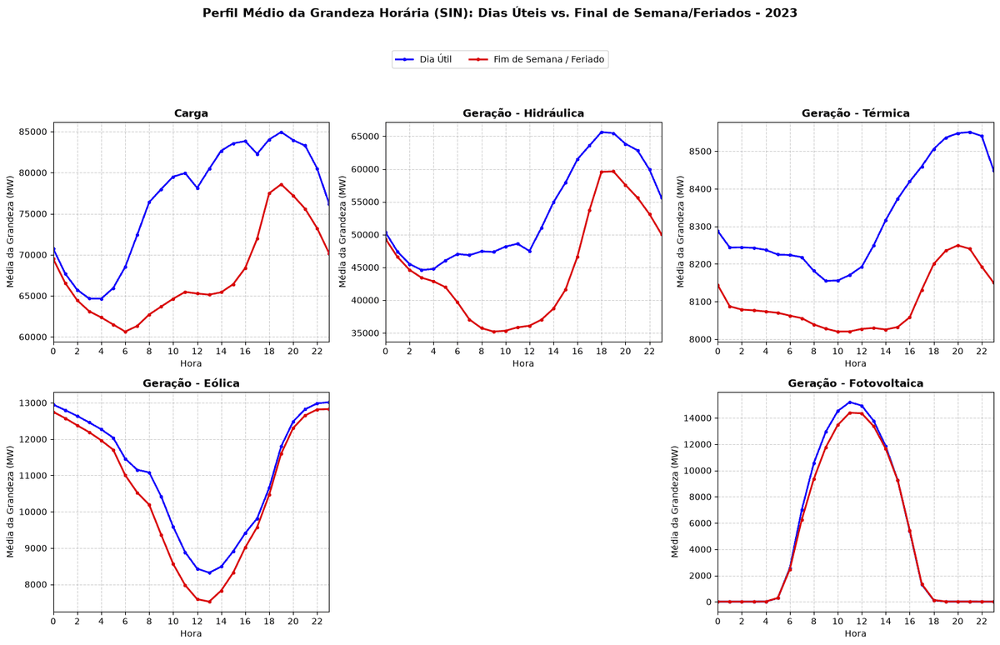

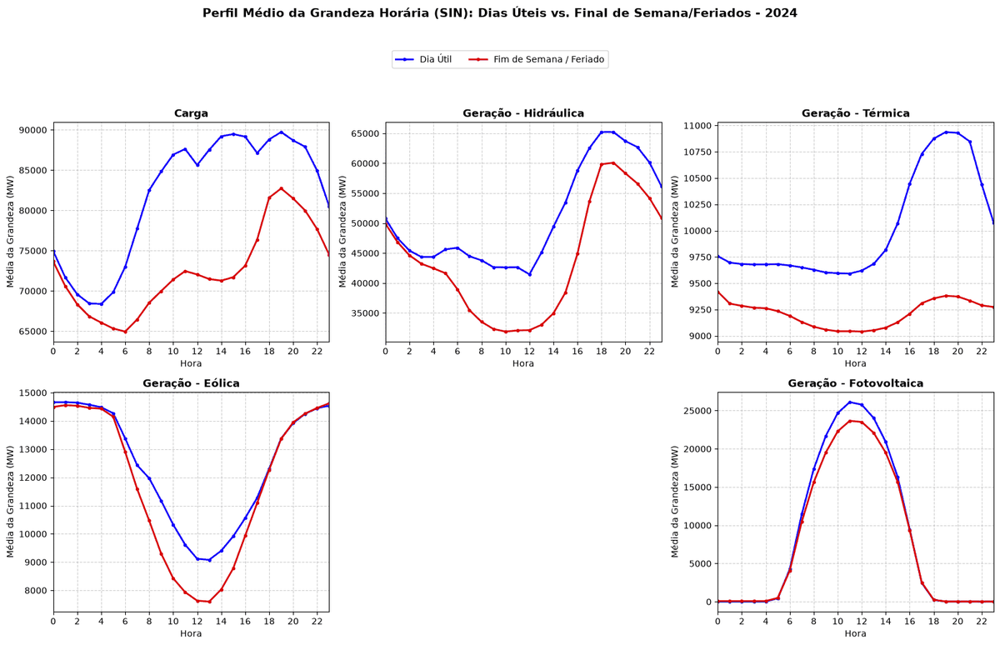

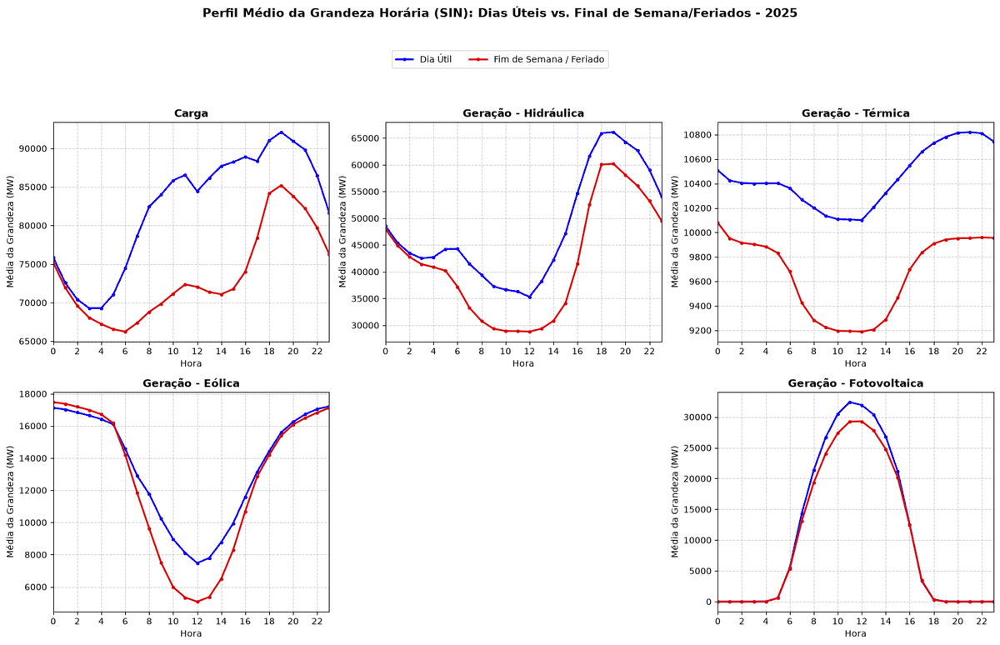

In [10]:
# Script para plotar o perfil médio da grandeza horária do SIN, comparando dias úteis e fins de semana/feriados

cols_grandeza = [
    'val_carga',
    'val_gerhidraulica',
    'val_gertermica',
    'val_gereolica',
    'val_gersolar'
]

nomes_grandeza = [
    'Carga',
    'Geração - Hidráulica',
    'Geração - Térmica',
    'Geração - Eólica',
    'Geração - Fotovoltaica'
]

posicoes_grid = [
    (0, 0),  # Carga
    (0, 1),  # Geração - Hidráulica 
    (0, 2),  # Geração - Térmica
    (1, 0),  # Geração - Eólica 
    (1, 2)   # Geração - Fotovoltaica 
]

dias_uteis = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira']

for ano, df in dataframes.items():
    # 1. Filtra os dados do SIN
    df_sin = df[df['id_subsistema'] == 'SIN'].copy()
    
    # 2. Classifica o tipo de dia e extrai a hora (0 a 23)
    df_sin['grupo_dia'] = df_sin['tipo_dia'].apply(
        lambda x: 'Dia Útil' if x in dias_uteis else 'Fim de Semana / Feriado'
    )
    df_sin['hora'] = df_sin['din_instante'].dt.hour

    # 3. Calcula a média horária
    df_perfil_var = df_sin.groupby(['grupo_dia', 'hora'])[cols_grandeza].mean().unstack(level=0)

    # 4. Configuração da figura
    fig = plt.figure(figsize=(16, 10))
    gs = gridspec.GridSpec(nrows=2, ncols=3, figure=fig)

    for i, col in enumerate(cols_grandeza):
        linha, coluna = posicoes_grid[i]
        ax = fig.add_subplot(gs[linha, coluna])
        
        dados_plot = df_perfil_var[col]
        
        dados_plot.plot(
            kind='line',
            ax=ax,
            linewidth=2,
            marker='o',
            markersize=3,
            color=["#1201fc", "#d90202"]
        )

        ax.set_title(f'{nomes_grandeza[i]}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Hora', fontsize=10)
        ax.set_ylabel('Média da Grandeza (MW)', fontsize=10)
        
        ax.set_xlim(0, 23)
        ax.set_xticks(range(0, 24, 2))
        
        ax.tick_params(labelbottom=True)
        ax.grid(True, linestyle='--', alpha=0.6)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()


    plt.suptitle(
        f'Perfil Médio da Grandeza Horária (SIN): Dias Úteis vs. Final de Semana/Feriados - {ano}',
        fontsize=14,
        fontweight='bold',
        y=1.02
    )
    
    fig.legend(handles, labels, loc='lower center',
               bbox_to_anchor=(0.5, 0.915), ncol=2, fontsize=10, title_fontsize=10)
    
    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.show()

**4.3 Análise horária do Perfil Médio da Variação das Grandezas do SIN: comparativo Dia Útil e Final de Semana/Feriado**

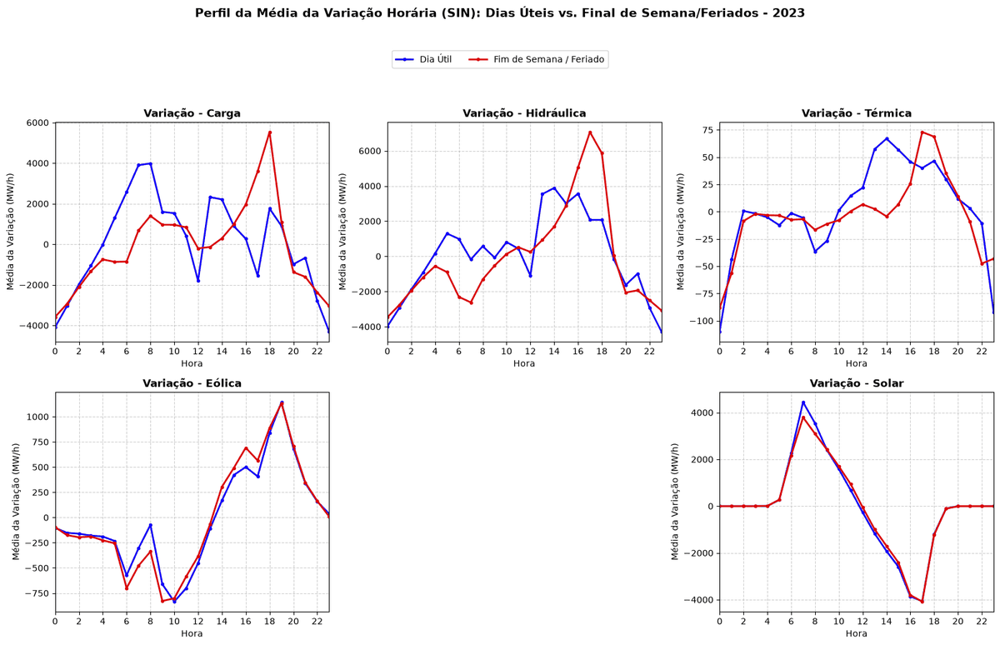

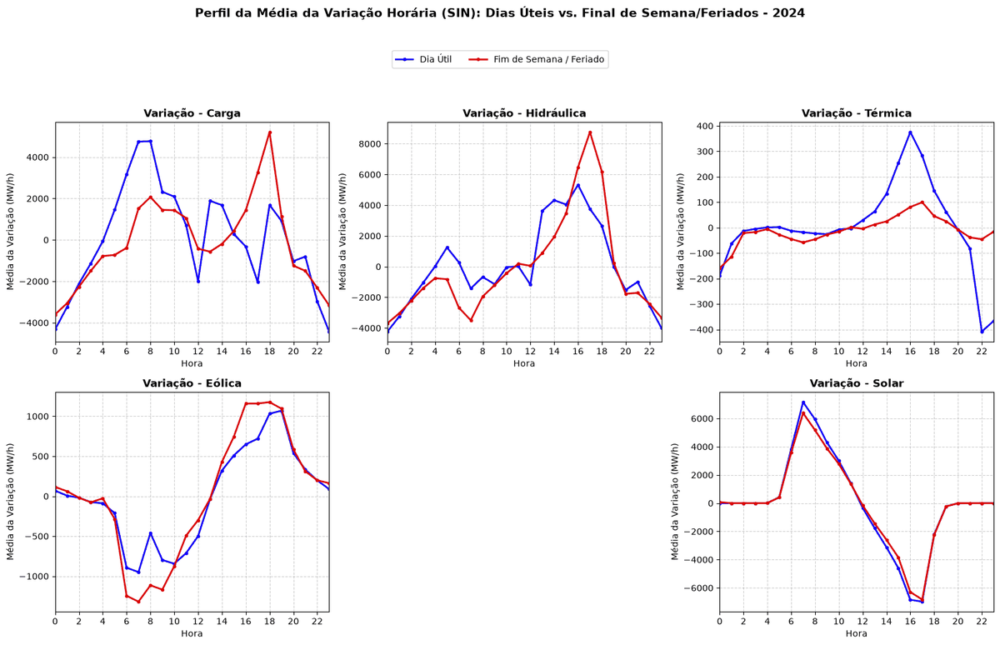

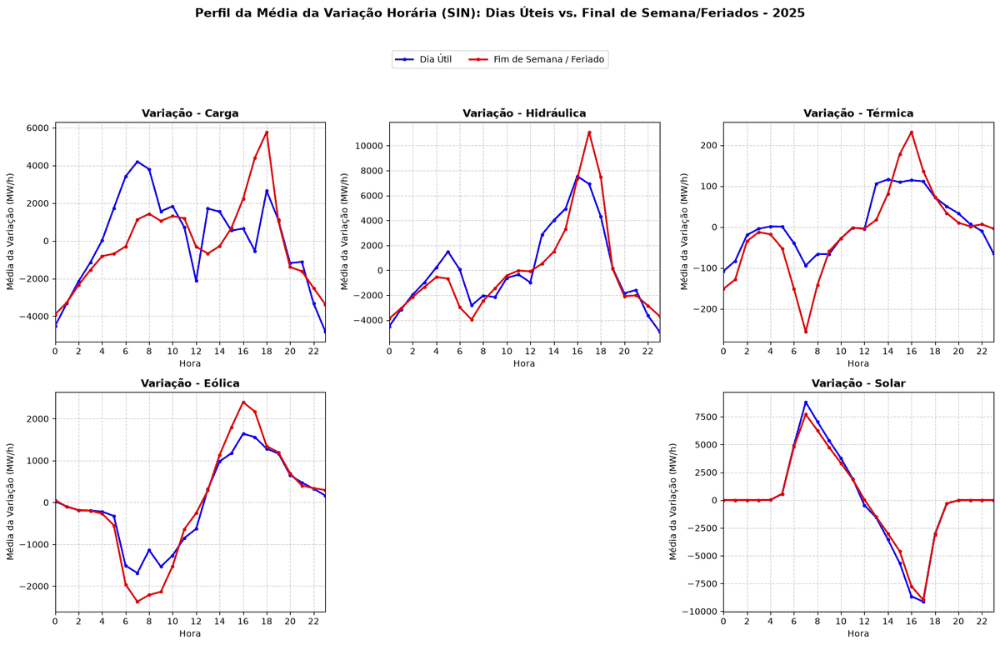

In [11]:
# Script para plotar o perfil médio da variação da grandeza horária do SIN, comparando dias úteis e fins de semana/feriados

cols_variacao = [
    'var_val_carga',
    'var_val_gerhidraulica',
    'var_val_gertermica',
    'var_val_gereolica',
    'var_val_gersolar',
]

nomes_variacao = [
    'Variação - Carga',
    'Variação - Hidráulica',
    'Variação - Térmica',
    'Variação - Eólica',
    'Variação - Solar'
]

dias_uteis = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira']

for ano, df in dataframes.items():
    # 1. Filtra os dados do SIN
    df_sin = df[df['id_subsistema'] == 'SIN'].copy()
    
    # 2. Classifica o tipo de dia e extrai a hora (0 a 23)
    df_sin['grupo_dia'] = df_sin['tipo_dia'].apply(
        lambda x: 'Dia Útil' if x in dias_uteis else 'Fim de Semana / Feriado'
    )
    df_sin['hora'] = df_sin['din_instante'].dt.hour

    # 3. Calcula a média horária da variação (derivada) agrupando por grupo de dia e hora
    df_perfil_var = df_sin.groupby(['grupo_dia', 'hora'])[cols_variacao].mean().unstack(level=0)

    # 4. Configuração da figura
    fig = plt.figure(figsize=(16, 10))
    gs = gridspec.GridSpec(nrows=2, ncols=3, figure=fig)
    
    for i, col in enumerate(cols_variacao):
        linha, coluna = posicoes_grid[i]
        ax = fig.add_subplot(gs[linha, coluna])
            
        dados_plot = df_perfil_var[col]
            
        dados_plot.plot(
            kind='line',
            ax=ax,
            linewidth=2,
            marker='o',
            markersize=3,
            color=["#1201fc", "#d90202"]
        )
    
        ax.set_title(f'{nomes_variacao[i]}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Hora', fontsize=10)
        ax.set_ylabel('Média da Variação (MW/h)', fontsize=10)
            
        ax.set_xlim(0, 23)
        ax.set_xticks(range(0, 24, 2))
            
        ax.tick_params(labelbottom=True)
        ax.grid(True, linestyle='--', alpha=0.6)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()
    
    plt.suptitle(
        f'Perfil da Média da Variação Horária (SIN): Dias Úteis vs. Final de Semana/Feriados - {ano}',
        fontsize=14,
        fontweight='bold',
        y=1.02
    )
        
    fig.legend(handles, labels, loc='lower center',
               bbox_to_anchor=(0.5, 0.915), ncol=2, fontsize=10, title_fontsize=10)
    
    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.show()

**4.4 Análise horária do Perfil Médio das Grandezas do SIN: comparativo Sazonal (Inverno e Verão)**

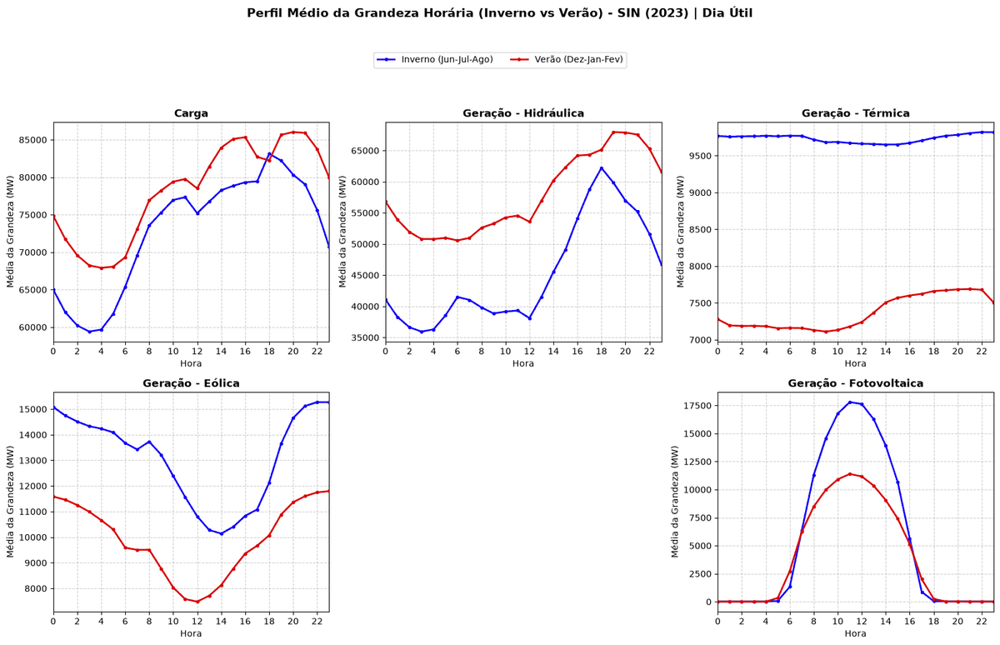

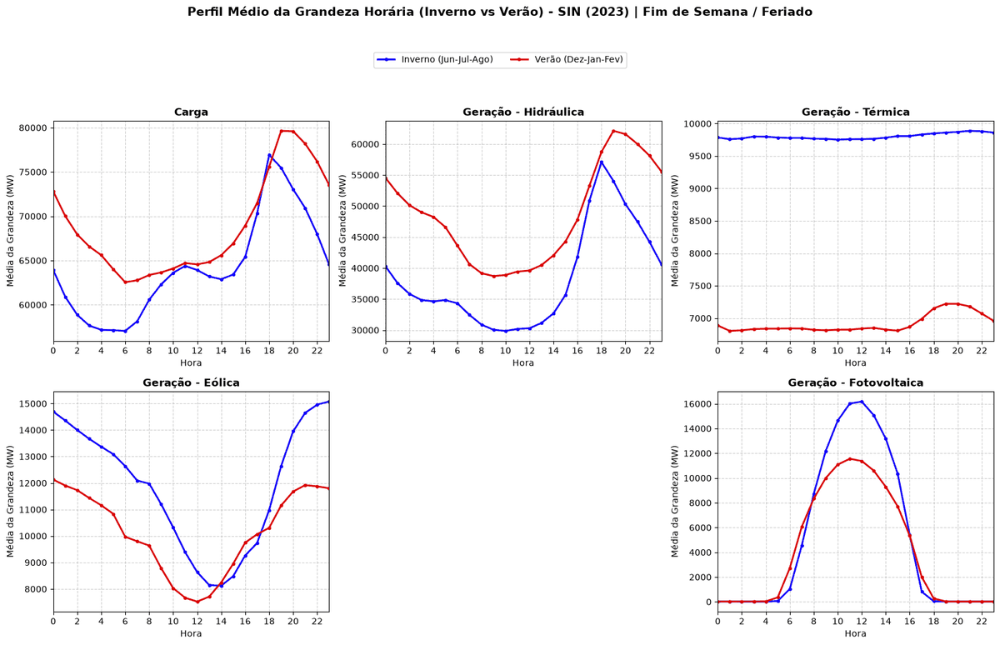

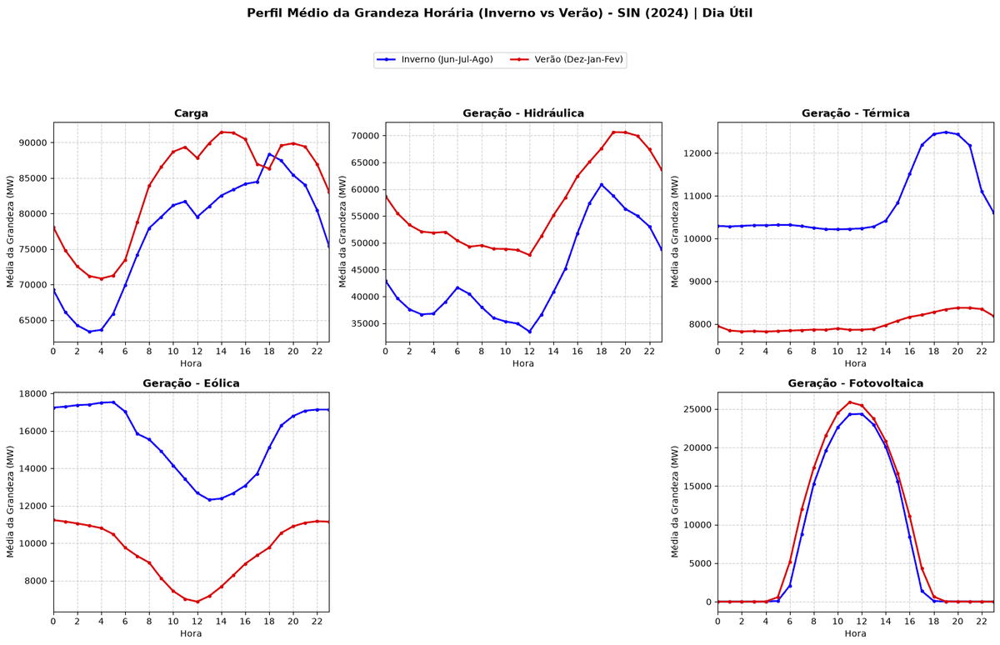

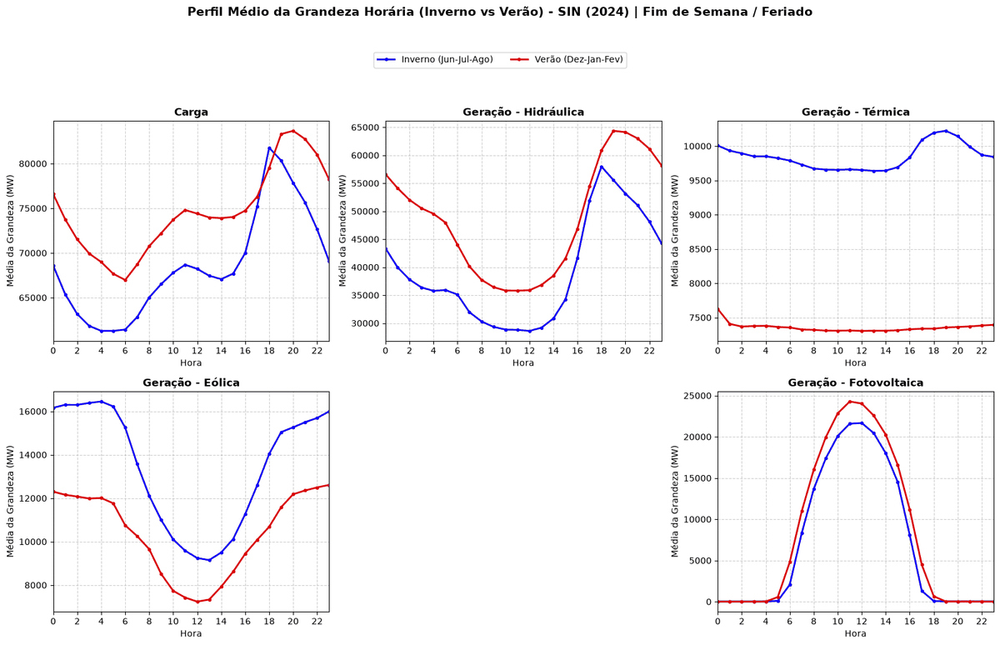

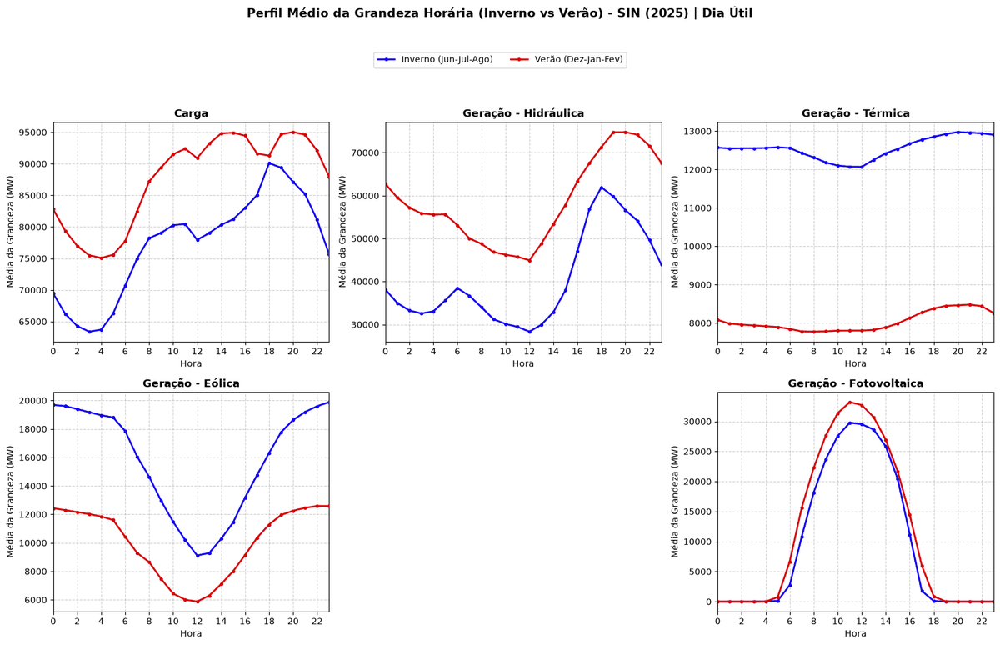

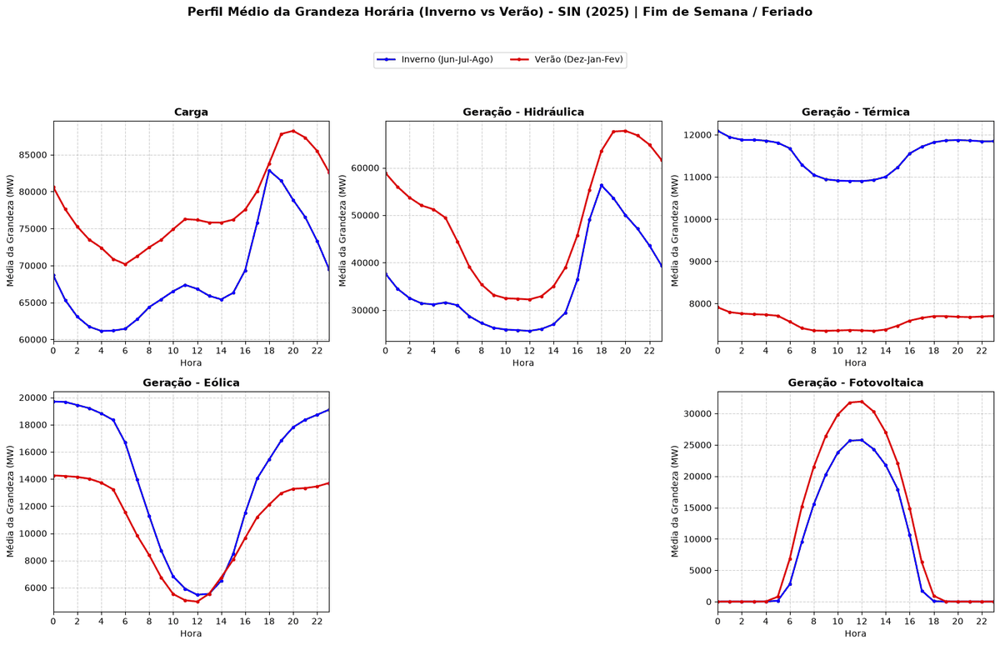

In [12]:
# Script para gerar comparativos sazonais (Inverno vs Verão) das grandezas do SIN, por ano e tipo de período (Dia Útil vs Fim de Semana/Feriado)

lista_consolidada = []
dias_uteis = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira']

for ano, df in dataframes.items():
    # Filtra dados do SIN
    df_sin = df[df['id_subsistema'] == 'SIN'].copy()
    
    # Classifica o tipo de dia e extrai a hora e mês
    df_sin['grupo_dia'] = df_sin['tipo_dia'].apply(
        lambda x: 'Dia Útil' if x in dias_uteis else 'Fim de Semana / Feriado'
    )
    df_sin['hora'] = df_sin['din_instante'].dt.hour
    df_sin['mes'] = df_sin['din_instante'].dt.month
    df_sin['ano'] = str(ano)  # Cria a coluna identificadora do ano
    
    # Mapeia os meses para as estações solicitadas | Inverno: Junho (6), Julho (7), Agosto (8) | Verão: Dezembro (12), Janeiro (1), Fevereiro (2)
    def define_estacao(mes):
        if mes in [6, 7, 8]:
            return 'Inverno (Jun-Jul-Ago)'
        elif mes in [12, 1, 2]:
            return 'Verão (Dez-Jan-Fev)'
        return None

    df_sin['estacao'] = df_sin['mes'].apply(define_estacao)
    
    # Remove registros que não pertencem ao inverno ou verão definidos
    df_sin = df_sin.dropna(subset=['estacao'])
    lista_consolidada.append(df_sin)

df_total = pd.concat(lista_consolidada, ignore_index=True)

cols_grandezas = [
    'val_carga',
    'val_gerhidraulica',
    'val_gertermica',
    'val_gereolica',
    'val_gersolar'
]

nomes_grandezas = [
    'Carga',
    'Geração - Hidráulica',
    'Geração - Térmica',
    'Geração - Eólica',
    'Geração - Fotovoltaica'
]

posicoes_grid = [
    (0, 0),  # Carga
    (0, 1),  # Geração - Hidráulica 
    (0, 2),  # Geração - Térmica
    (1, 0),  # Geração - Eólica 
    (1, 2)   # Geração - Fotovoltaica 
]

cores_estacoes = {
    'Inverno (Jun-Jul-Ago)': '#1201fc', 
    'Verão (Dez-Jan-Fev)': '#d90202'     
}

anos_alvo = sorted(df_total['ano'].unique())
tipos_periodo = ['Dia Útil', 'Fim de Semana / Feriado']

# 2. Loops para gerar as figuras por Ano, por Tipo de Período e comparando as Estações
for ano_str in anos_alvo:
    df_ano_atual = df_total[df_total['ano'] == ano_str]
    
    if df_ano_atual.empty:
        continue
        
    for periodo in tipos_periodo:
        df_periodo = df_ano_atual[df_ano_atual['grupo_dia'] == periodo]
        
        if df_periodo.empty:
            continue
            
        # Configuração da figura com GridSpec (2 linhas x 3 colunas)
        fig = plt.figure(figsize=(16, 10))
        gs = gridspec.GridSpec(nrows=2, ncols=3, figure=fig)
        
        for i, col in enumerate(cols_grandezas):
            linha, coluna = posicoes_grid[i]
            ax = fig.add_subplot(gs[linha, coluna])
            
            # Plota a curva de cada estação no mesmo subplot para comparação
            for estacao, cor in cores_estacoes.items():
                df_est = df_periodo[df_periodo['estacao'] == estacao]
                
                if not df_est.empty:
                    perfil_est = df_est.groupby('hora')[col].mean()
                    
                    ax.plot(
                        perfil_est.index,
                        perfil_est.values,
                        label=estacao,
                        linewidth=2,
                        marker='o',
                        markersize=3,
                        color=cor
                    )
            
            ax.set_title(f'{nomes_grandezas[i]}', fontsize=12, fontweight='bold')
            ax.set_xlabel('Hora', fontsize=10)
            ax.set_ylabel('Média da Grandeza (MW)', fontsize=10)
            ax.set_xlim(0, 23)
            ax.set_xticks(range(0, 24, 2))
            
            ax.tick_params(labelbottom=True)
            ax.grid(True, linestyle='--', alpha=0.6)
            
            if i == 0:
                handles, labels = ax.get_legend_handles_labels()


        plt.suptitle(
            f'Perfil Médio da Grandeza Horária (Inverno vs Verão) - SIN ({ano_str}) | {periodo}',
            fontsize=14,
            fontweight='bold',
            y=1.02
        )
        
        fig.legend(handles, labels, loc='lower center',
                    bbox_to_anchor=(0.5, 0.915), ncol=2, fontsize=10, title_fontsize=10)
            
        plt.tight_layout(rect=[0, 0, 1, 0.91])
        plt.show()

**4.5 Análise horária do Perfil Médio da Variação das Grandezas do SIN: comparativo Sazonal (Inverno e Verão)**

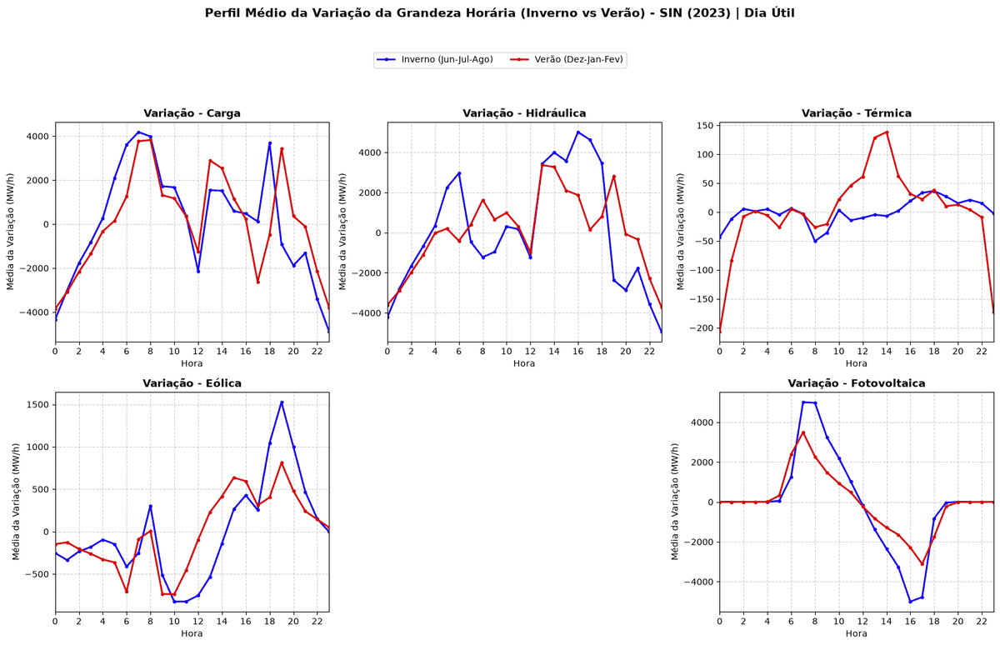

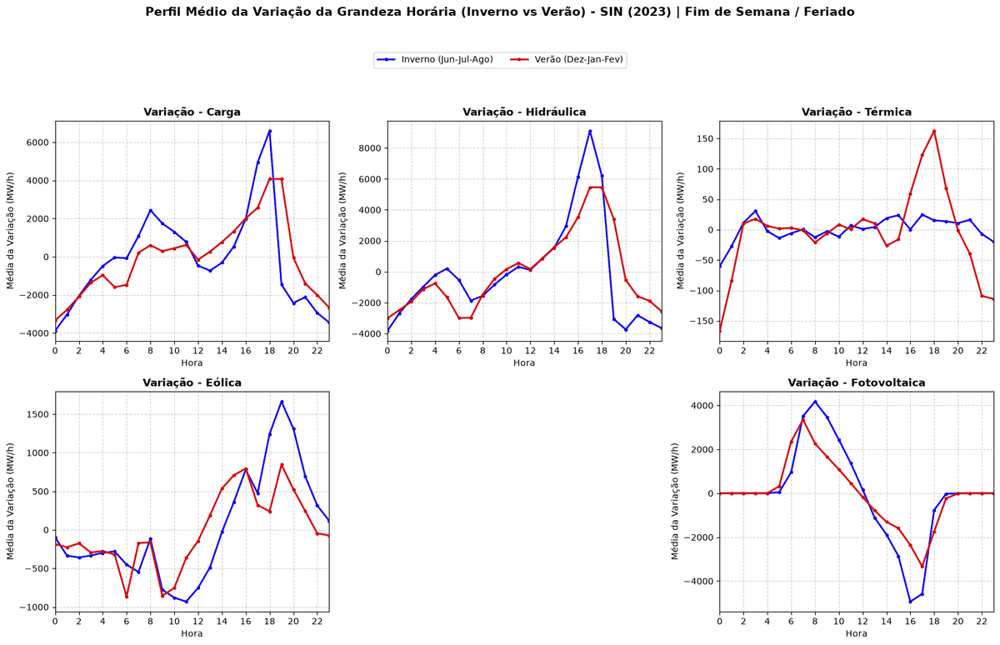

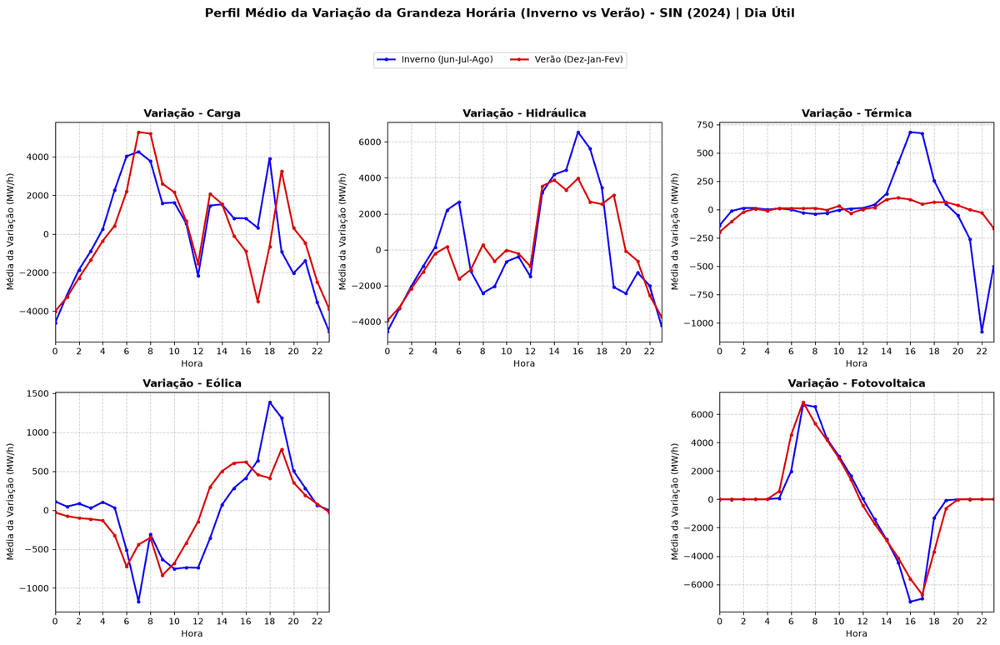

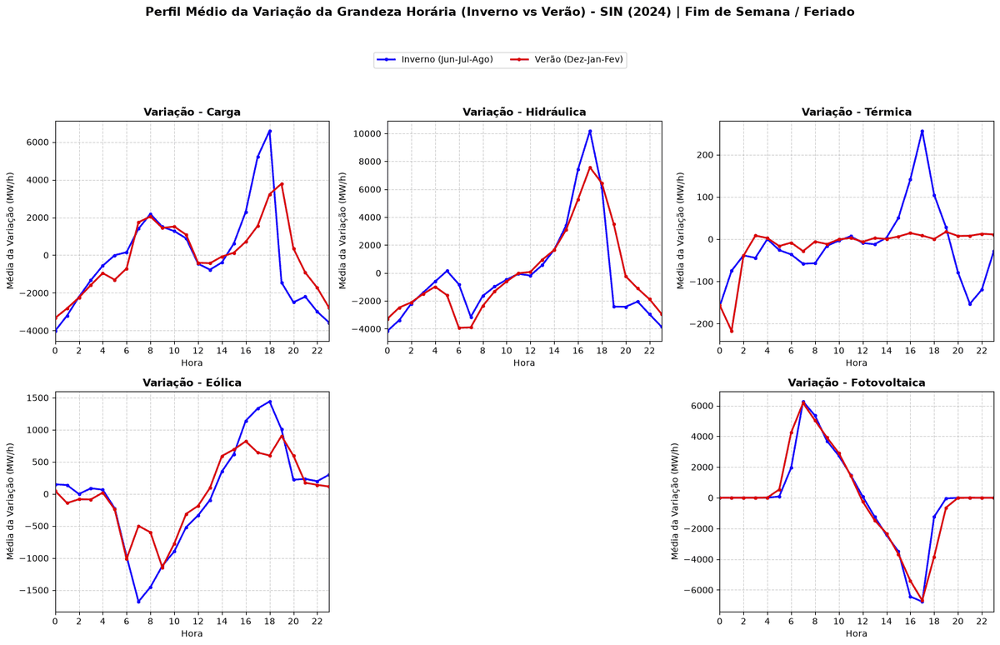

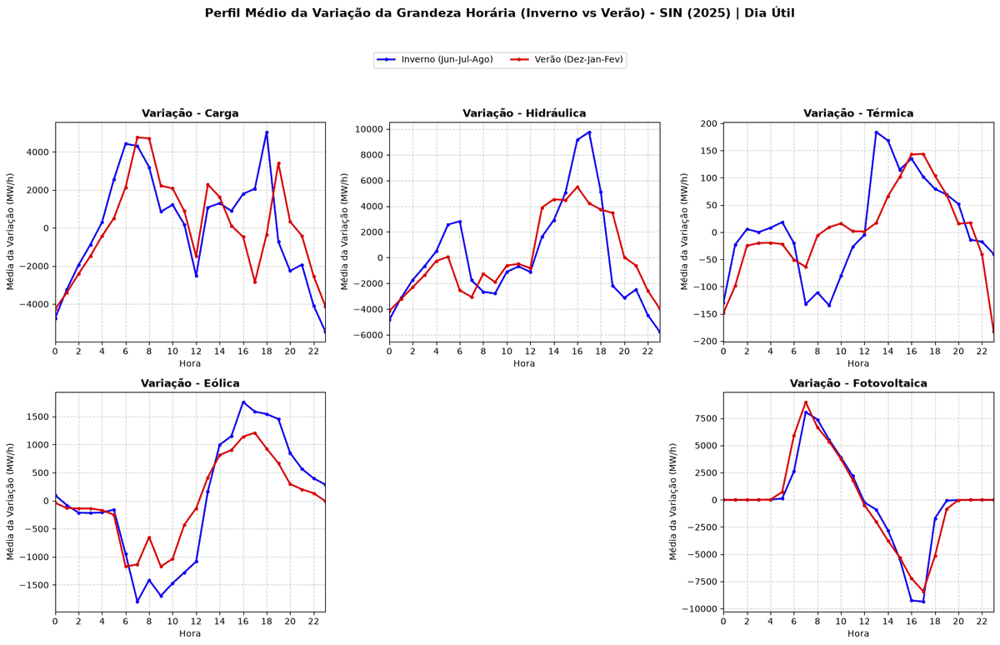

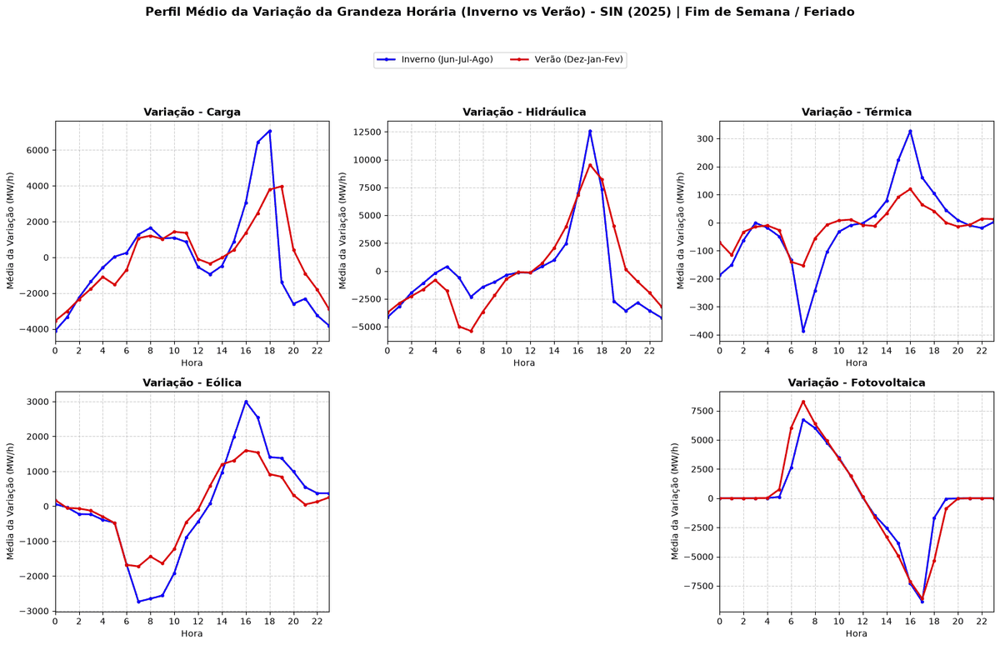

In [13]:
# Script para gerar comparativos sazonais (Inverno vs Verão) da variação das grandezas do SIN, por ano e tipo de período (Dia Útil vs Fim de Semana/Feriado)

lista_consolidada = []
dias_uteis = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira']

for ano, df in dataframes.items():
    # Filtra dados do SIN
    df_sin = df[df['id_subsistema'] == 'SIN'].copy()
    
    # Classifica o tipo de dia e extrai a hora e mês
    df_sin['grupo_dia'] = df_sin['tipo_dia'].apply(
        lambda x: 'Dia Útil' if x in dias_uteis else 'Fim de Semana / Feriado'
    )
    df_sin['hora'] = df_sin['din_instante'].dt.hour
    df_sin['mes'] = df_sin['din_instante'].dt.month
    df_sin['ano'] = str(ano)  # Cria a coluna identificadora do ano
    
    # Mapeia os meses para as estações solicitadas | Inverno: Junho (6), Julho (7), Agosto (8) | Verão: Dezembro (12), Janeiro (1), Fevereiro (2)
    def define_estacao(mes):
        if mes in [6, 7, 8]:
            return 'Inverno (Jun-Jul-Ago)'
        elif mes in [12, 1, 2]:
            return 'Verão (Dez-Jan-Fev)'
        return None

    df_sin['estacao'] = df_sin['mes'].apply(define_estacao)
    
    # Remove registros que não pertencem ao inverno ou verão definidos
    df_sin = df_sin.dropna(subset=['estacao'])
    lista_consolidada.append(df_sin)

df_total = pd.concat(lista_consolidada, ignore_index=True)

cols_variacao = [
    'var_val_carga',
    'var_val_gerhidraulica',
    'var_val_gertermica',
    'var_val_gereolica',
    'var_val_gersolar'
]

nomes_variacao = [
    'Variação - Carga',
    'Variação - Hidráulica',
    'Variação - Térmica',
    'Variação - Eólica',
    'Variação - Fotovoltaica'
]

posicoes_grid = [
    (0, 0),  # Variação - Carga
    (0, 1),  # Variação - Hidráulica 
    (0, 2),  # Variação - Térmica
    (1, 0),  # Variação - Eólica 
    (1, 2)   # Variação - Fotovoltaica 
]

# Paleta de cores para comparar as estações
cores_estacoes = {
    'Inverno (Jun-Jul-Ago)': '#1201fc', 
    'Verão (Dez-Jan-Fev)': '#d90202'      
}

anos_alvo = sorted(df_total['ano'].unique())
tipos_periodo = ['Dia Útil', 'Fim de Semana / Feriado']

# 2. Loops para gerar as figuras por Ano, por Tipo de Período e comparando as Estações
for ano_str in anos_alvo:
    df_ano_atual = df_total[df_total['ano'] == ano_str]
    
    if df_ano_atual.empty:
        continue
        
    for periodo in tipos_periodo:
        df_periodo = df_ano_atual[df_ano_atual['grupo_dia'] == periodo]
        
        if df_periodo.empty:
            continue
            
        fig = plt.figure(figsize=(16, 10))
        gs = gridspec.GridSpec(nrows=2, ncols=3, figure=fig)
        
        for i, col in enumerate(cols_variacao):
            linha, coluna = posicoes_grid[i]
            ax = fig.add_subplot(gs[linha, coluna])
            
            for estacao, cor in cores_estacoes.items():
                df_est = df_periodo[df_periodo['estacao'] == estacao]
                
                if not df_est.empty:
                    perfil_est = df_est.groupby('hora')[col].mean()
                    
                    ax.plot(
                        perfil_est.index,
                        perfil_est.values,
                        label=estacao,
                        linewidth=2,
                        marker='o',
                        markersize=3,
                        color=cor
                    )
            
            ax.set_title(f'{nomes_variacao[i]}', fontsize=12, fontweight='bold')
            ax.set_xlabel('Hora', fontsize=10)
            ax.set_ylabel('Média da Variação (MW/h)', fontsize=10)
            
            ax.set_xlim(0, 23)
            ax.set_xticks(range(0, 24, 2))
            
            ax.tick_params(labelbottom=True)
            ax.grid(True, linestyle='--', alpha=0.6)
            
            if i == 0:
                handles, labels = ax.get_legend_handles_labels()

        plt.suptitle(
            f'Perfil Médio da Variação da Grandeza Horária (Inverno vs Verão) - SIN ({ano_str}) | {periodo}',
            fontsize=14,
            fontweight='bold',
            y=1.02
        )
        
        fig.legend(handles, labels, loc='lower center',
                    bbox_to_anchor=(0.5, 0.915), ncol=2, fontsize=10, title_fontsize=10)
                    
        plt.tight_layout(rect=[0, 0, 1, 0.91])
        plt.show()

**4.6 Análise horária do Perfil Médio das Grandezas do SIN: comparativo Interanual (2023, 2024 e 2025)**

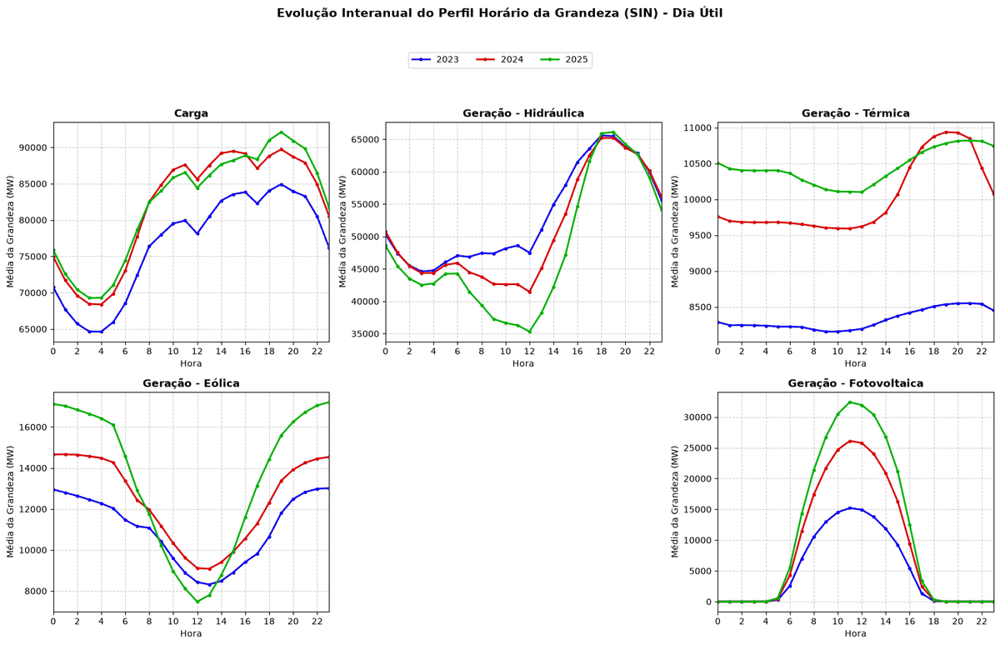

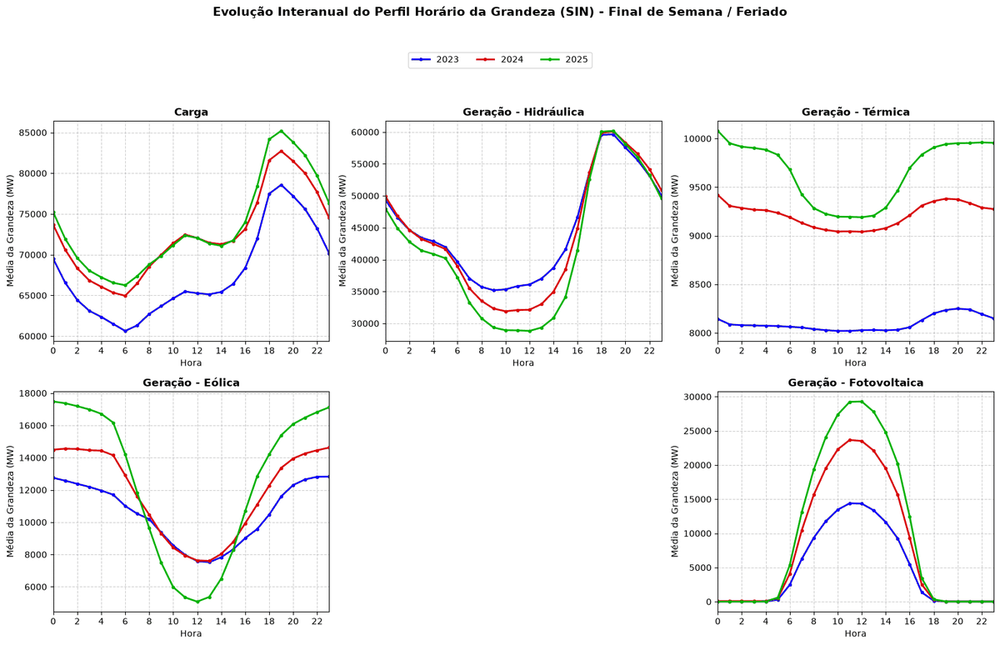

In [14]:
# Script para análise do perfil horário das grandezas do SIN, comparando os anos 2023, 2024 e 2025

lista_consolidada = []

dias_uteis = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira']

for ano, df in dataframes.items():
    # Filtra dados do SIN
    df_sin = df[df['id_subsistema'] == 'SIN'].copy()
    
    # Classifica o tipo de dia e extrai a hora
    df_sin['grupo_dia'] = df_sin['tipo_dia'].apply(
        lambda x: 'Dia Útil' if x in dias_uteis else 'Final de Semana / Feriado'
    )
    df_sin['hora'] = df_sin['din_instante'].dt.hour
    df_sin['ano'] = str(ano)  # Cria a coluna identificadora do ano
    
    lista_consolidada.append(df_sin)

df_total = pd.concat(lista_consolidada, ignore_index=True)

cols_grandezas = [
    'val_carga',
    'val_gerhidraulica',
    'val_gertermica',
    'val_gereolica',
    'val_gersolar'
]

nomes_grandezas = [
    'Carga',
    'Geração - Hidráulica',
    'Geração - Térmica',
    'Geração - Eólica',
    'Geração - Fotovoltaica'
]

posicoes_grid = [
    (0, 0),  # Carga
    (0, 1),  # Geração - Hidráulica 
    (0, 2),  # Geração - Térmica
    (1, 0),  # Geração - Eólica 
    (1, 2)   # Geração - Fotovoltaica 
]

cores_anos = {'2023': '#1201fc', '2024': '#d90202', '2025': "#00b100"}

# 1. Loop para gerar duas figuras: uma para Dias Úteis e outra para Finais de Semana/Feriados
tipos_periodo = ['Dia Útil', 'Final de Semana / Feriado']

for periodo in tipos_periodo:
    # Filtra o DataFrame apenas para o grupo de dia atual
    df_periodo = df_total[df_total['grupo_dia'] == periodo]
    
    # Calcula a média horária agrupando por Ano e Hora
    df_perfil = df_periodo.groupby(['ano', 'hora'])[cols_grandezas].mean().unstack(level=0)
    
    fig = plt.figure(figsize=(16, 10))
    gs = gridspec.GridSpec(nrows=2, ncols=3, figure=fig)
    
    for i, col in enumerate(cols_grandezas):
        linha, coluna = posicoes_grid[i]
        ax = fig.add_subplot(gs[linha, coluna])
        
        dados_grandeza = df_perfil[col]
        
        for ano_str in sorted(cores_anos.keys()):
            if ano_str in dados_grandeza.columns:
                ax.plot(
                    dados_grandeza.index,             
                    dados_grandeza[ano_str],          
                    label=ano_str,
                    linewidth=2,
                    marker='o',
                    markersize=3,
                    color=cores_anos[ano_str]
                )
        
        ax.set_title(f'{nomes_grandezas[i]}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Hora', fontsize=10)
        ax.set_ylabel('Média da Grandeza (MW)', fontsize=10)
        
        ax.set_xlim(0, 23)
        ax.set_xticks(range(0, 24, 2))
        
        ax.tick_params(labelbottom=True)
        ax.grid(True, linestyle='--', alpha=0.6)
        
        if i == 0:
            handles, labels = ax.get_legend_handles_labels()

    plt.suptitle(
        f'Evolução Interanual do Perfil Horário da Grandeza (SIN) - {periodo}',
        fontsize=14,
        fontweight='bold',
        y=1.02
    )
    
    fig.legend(handles, labels, loc='lower center',
                bbox_to_anchor=(0.5, 0.915), ncol=3, fontsize=10, title_fontsize=10)
                        
    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.show()

**4.7 Análise horária do Perfil Médio da Variação das Grandezas do SIN: comparativo Interanual (2023, 2024 e 2025)**

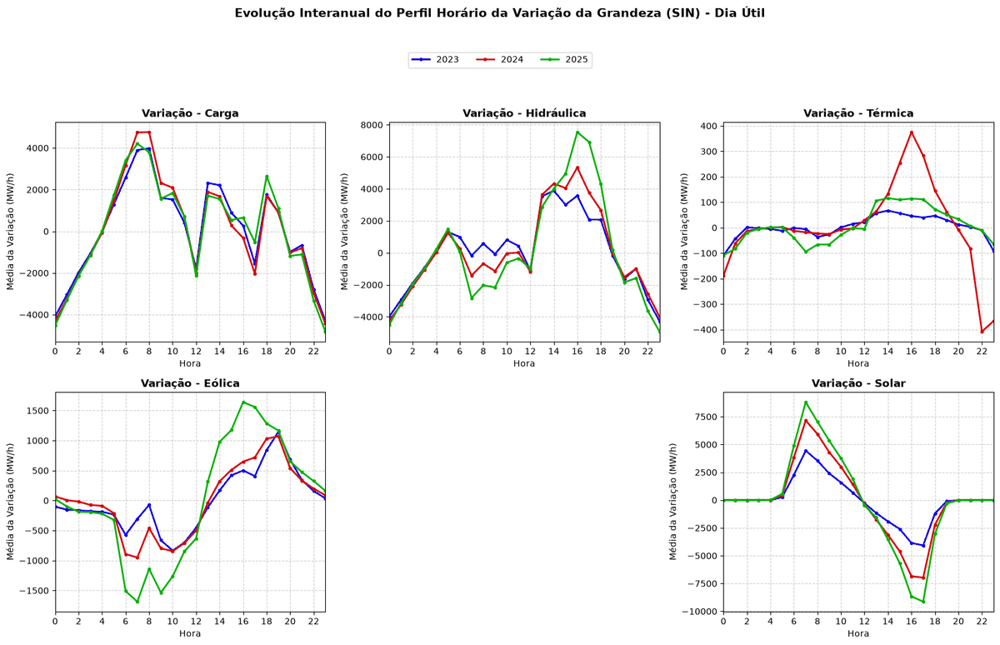

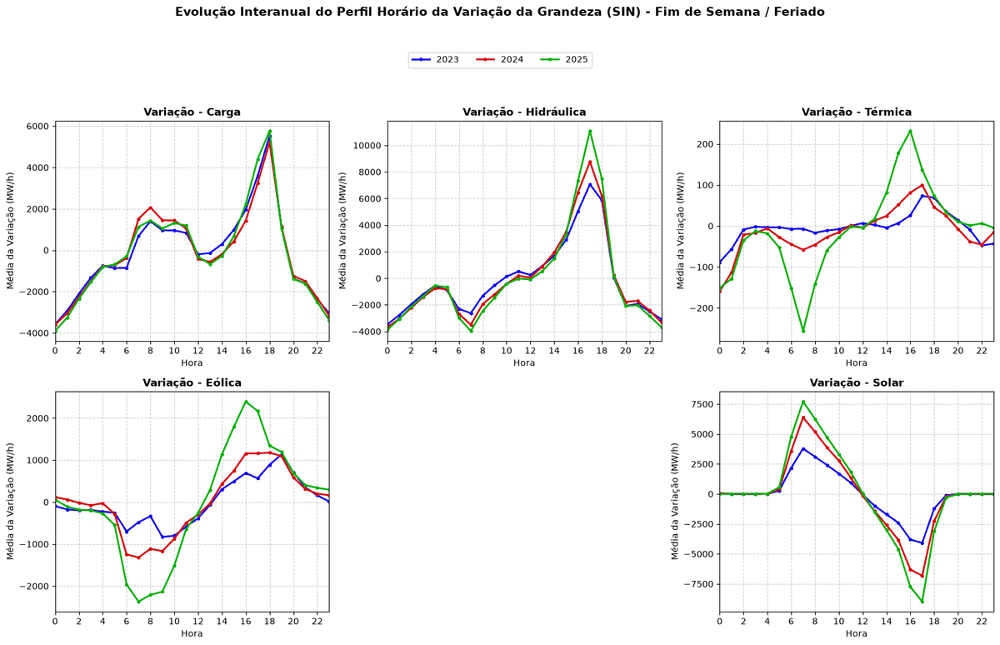

In [15]:
# Script para análise do perfil horário das variações das grandezas do SIN, comparando os anos 2023, 2024 e 2025

lista_consolidada = []

dias_uteis = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira']

for ano, df in dataframes.items():
    # Filtra os dados do SIN
    df_sin = df[df['id_subsistema'] == 'SIN'].copy()
    
    # Classifica o tipo de dia e extrai a hora
    df_sin['grupo_dia'] = df_sin['tipo_dia'].apply(
        lambda x: 'Dia Útil' if x in dias_uteis else 'Fim de Semana / Feriado'
    )
    df_sin['hora'] = df_sin['din_instante'].dt.hour
    df_sin['ano'] = str(ano)  # Cria a coluna identificadora do ano
    
    lista_consolidada.append(df_sin)

df_total = pd.concat(lista_consolidada, ignore_index=True)

cols_variacao = [
    'var_val_carga',
    'var_val_gerhidraulica',
    'var_val_gertermica',
    'var_val_gereolica',
    'var_val_gersolar'
]

nomes_variacao = [
    'Variação - Carga',
    'Variação - Hidráulica',
    'Variação - Térmica',
    'Variação - Eólica',
    'Variação - Solar'
]

posicoes_grid = [
    (0, 0),  # Carga
    (0, 1),  # Hidráulica
    (0, 2),  # Térmica
    (1, 0),  # Eólica
    (1, 2)   # Solar (fotovoltaica)
]

cores_anos = {'2023': '#1201fc', '2024': '#d90202', '2025': "#00b100"}

# 1. Loop para gerar duas figuras: uma para Dias Úteis e outra para Finais de Semana/Feriados
tipos_periodo = ['Dia Útil', 'Fim de Semana / Feriado']

for periodo in tipos_periodo:
    # Filtra o DataFrame apenas para o grupo de dia atual
    df_periodo = df_total[df_total['grupo_dia'] == periodo]
    
    # Calcula a média horária da variação agrupando por Ano e Hora
    df_perfil_var = df_periodo.groupby(['ano', 'hora'])[cols_variacao].mean().unstack(level=0)
    
    fig = plt.figure(figsize=(16, 10))
    gs = gridspec.GridSpec(nrows=2, ncols=3, figure=fig)
    
    for i, col in enumerate(cols_variacao):
        linha, coluna = posicoes_grid[i]
        ax = fig.add_subplot(gs[linha, coluna])
            
        dados_grandeza = df_perfil_var[col]
            
        for ano_str in sorted(cores_anos.keys()):
            if ano_str in dados_grandeza.columns:
                ax.plot(
                    dados_grandeza.index,             
                    dados_grandeza[ano_str],          
                    label=ano_str,
                    linewidth=2,
                    marker='o',
                    markersize=3,
                    color=cores_anos[ano_str]
                )
        
        ax.set_title(f'{nomes_variacao[i]}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Hora', fontsize=10)
        ax.set_ylabel('Média da Variação (MW/h)', fontsize=10)
            
        ax.set_xlim(0, 23)
        ax.set_xticks(range(0, 24, 2))
            
        ax.tick_params(labelbottom=True)
        ax.grid(True, linestyle='--', alpha=0.6)
    
        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
    
    plt.suptitle(
        f'Evolução Interanual do Perfil Horário da Variação da Grandeza (SIN) - {periodo}',
        fontsize=14,
        fontweight='bold',
        y=1.02
    )
        
    fig.legend(handles, labels, loc='lower center',
                bbox_to_anchor=(0.5, 0.915), ncol=3, fontsize=10, title_fontsize=10)
                            
    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.show()

**4.8 Análise horária do Perfil Médio das Grandezas do SIN: comparativo por submercado (N, NE, S e SE)**

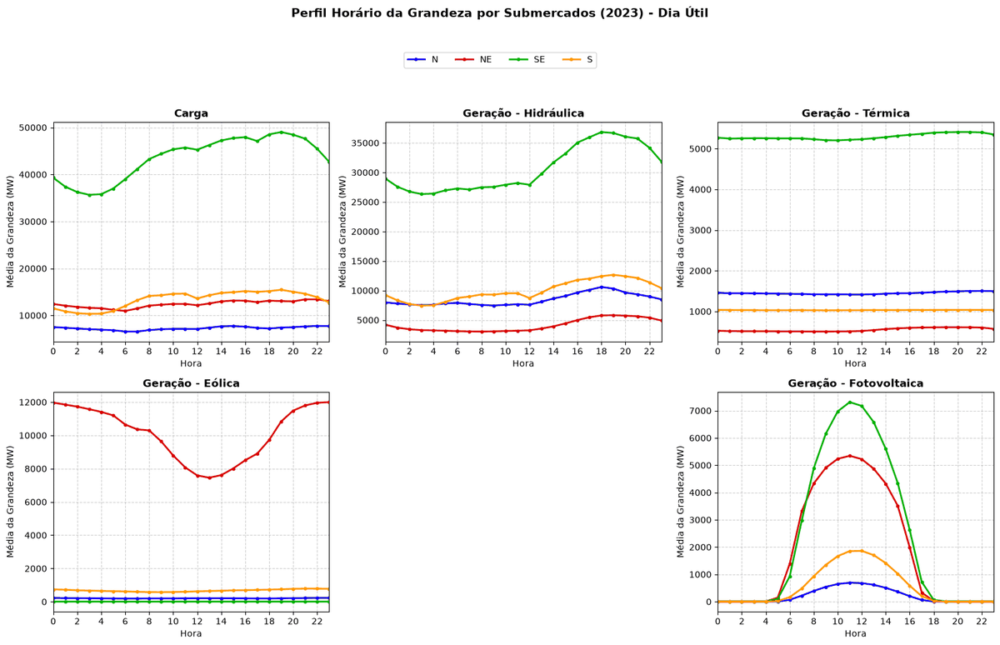

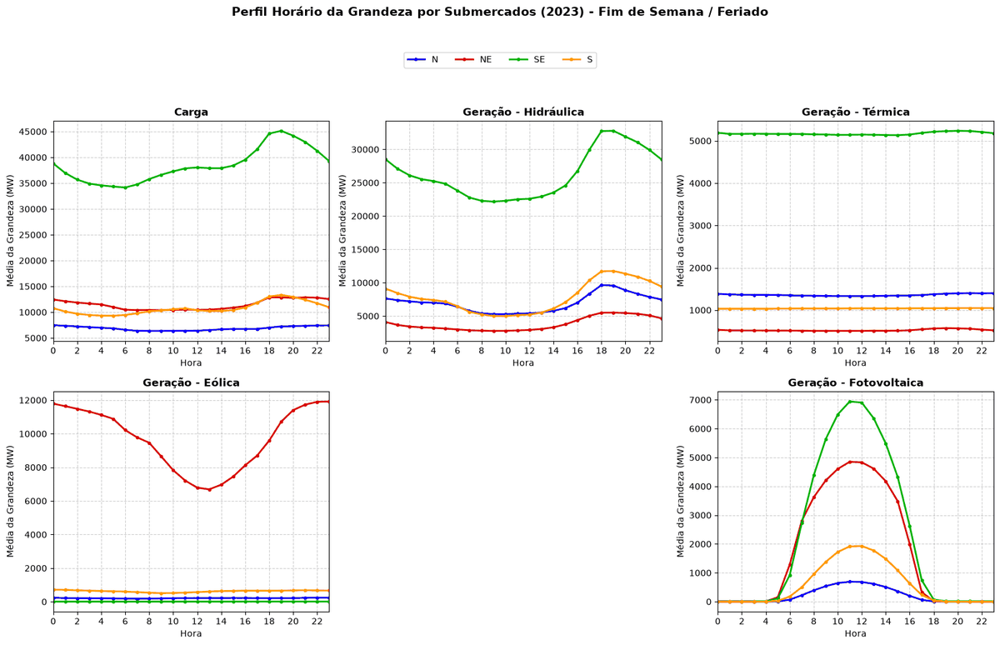

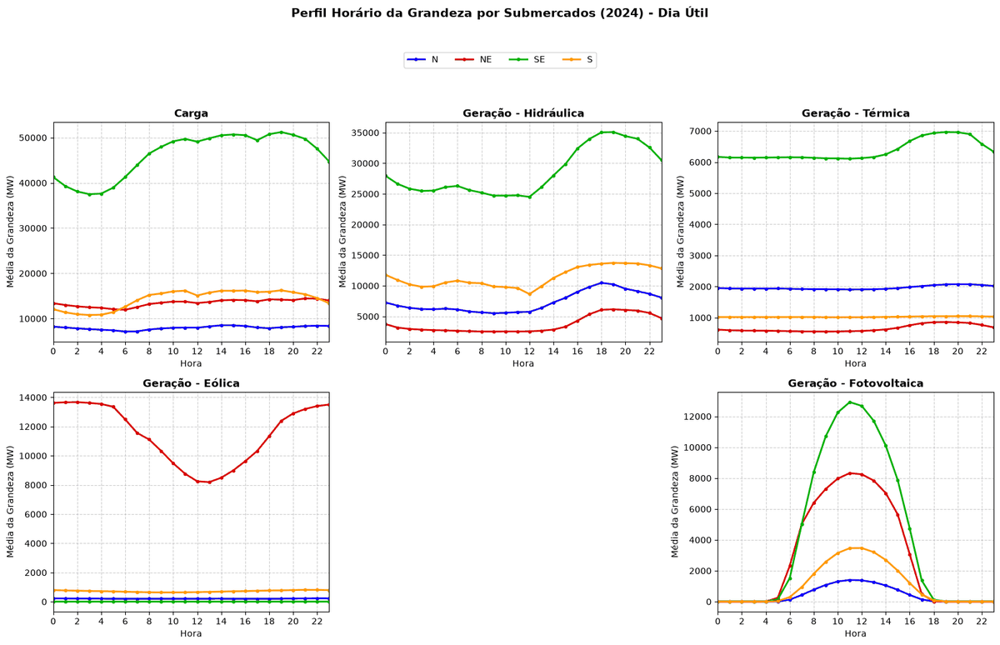

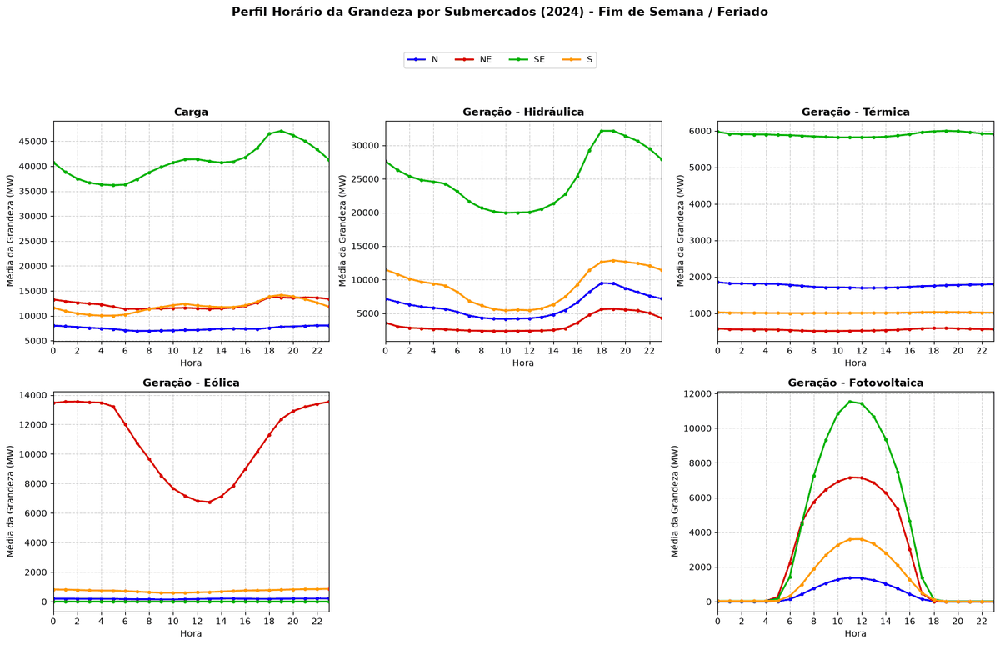

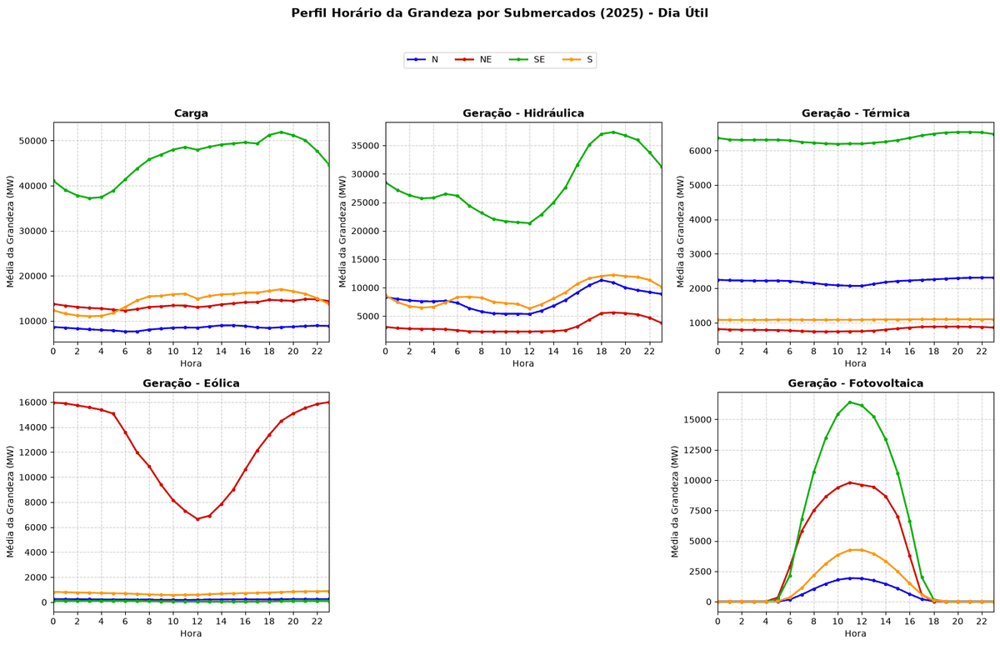

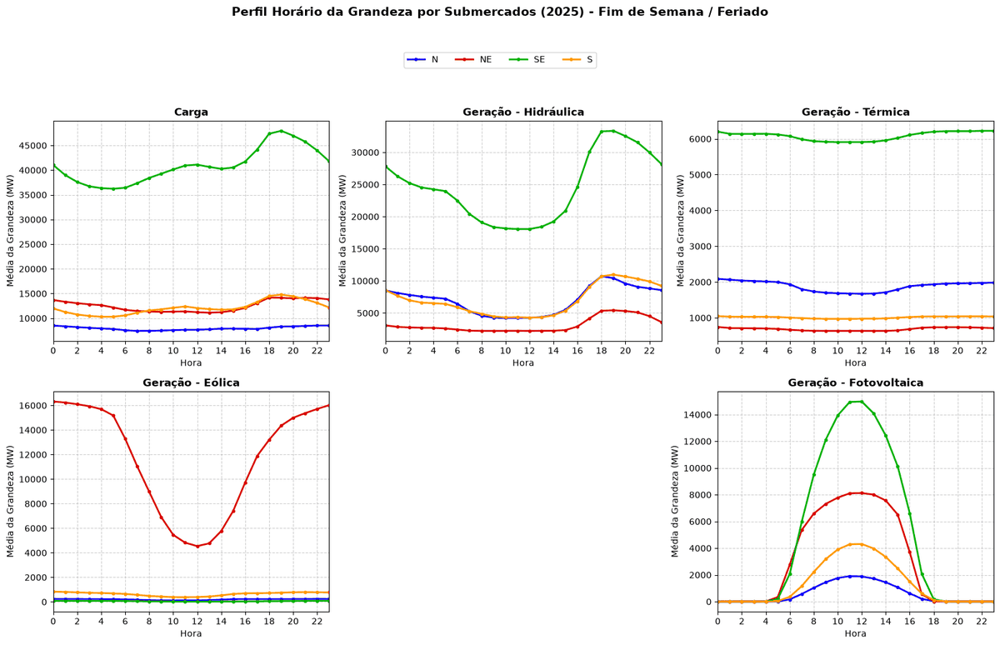

In [16]:
# Script para análise do perfil horário das grandezas por submercado, comparando os anos 2023, 2024 e 2025

lista_consolidada = []
dias_uteis = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira']

for ano, df in dataframes.items():
    df_ano = df.copy()
    
    # Classifica o tipo de dia e extrai a hora
    df_ano['grupo_dia'] = df_ano['tipo_dia'].apply(
        lambda x: 'Dia Útil' if x in dias_uteis else 'Fim de Semana / Feriado'
    )
    df_ano['hora'] = df_ano['din_instante'].dt.hour
    df_ano['ano'] = str(ano)
    
    lista_consolidada.append(df_ano)

df_total = pd.concat(lista_consolidada, ignore_index=True)

cols_grandezas = [
    'val_carga',
    'val_gerhidraulica',
    'val_gertermica',
    'val_gereolica',
    'val_gersolar'
]

nomes_grandezas = [
    'Carga',
    'Geração - Hidráulica',
    'Geração - Térmica',
    'Geração - Eólica',
    'Geração - Fotovoltaica'
]

posicoes_grid = [
    (0, 0),  # Carga
    (0, 1),  # Geração - Hidráulica 
    (0, 2),  # Geração - Térmica
    (1, 0),  # Geração - Eólica 
    (1, 2)   # Geração - Fotovoltaica 
]

cores_subs = {
    'N': '#1201fc',   
    'NE': '#d90202',  
    'SE': '#00b100',  
    'S': "#ff9900"    
}

submercados = ['N', 'NE', 'SE', 'S']
tipos_periodo = ['Dia Útil', 'Fim de Semana / Feriado']
anos_alvo = ['2023', '2024', '2025']

# 1. Loops para gerar as figuras por Ano e por Tipo de Período
for ano_str in anos_alvo:
    df_ano_atual = df_total[df_total['ano'] == ano_str]
    
    if df_ano_atual.empty:
        continue
        
    for periodo in tipos_periodo:
        df_periodo = df_ano_atual[df_ano_atual['grupo_dia'] == periodo]
        
        if df_periodo.empty:
            continue
            
        fig = plt.figure(figsize=(16, 10))
        gs = gridspec.GridSpec(nrows=2, ncols=3, figure=fig)
        
        for i, col in enumerate(cols_grandezas):
            linha, coluna = posicoes_grid[i]
            ax = fig.add_subplot(gs[linha, coluna])
            
            for sub in submercados:
                df_sub = df_periodo[df_periodo['id_subsistema'] == sub]
                
                if not df_sub.empty:
                    perfil_sub = df_sub.groupby('hora')[col].mean()
                    
                    ax.plot(
                        perfil_sub.index,
                        perfil_sub.values,
                        label=sub,
                        linewidth=2,
                        marker='o',
                        markersize=3,
                        color=cores_subs[sub]
                    )
            
            ax.set_title(f'{nomes_grandezas[i]}', fontsize=12, fontweight='bold')
            ax.set_xlabel('Hora', fontsize=10)
            ax.set_ylabel('Média da Grandeza (MW)', fontsize=10)
            
            ax.set_xlim(0, 23)
            ax.set_xticks(range(0, 24, 2))
            
            ax.tick_params(labelbottom=True)
            ax.grid(True, linestyle='--', alpha=0.6)
            
            if i == 0:
                handles, labels = ax.get_legend_handles_labels()

        plt.suptitle(
            f'Perfil Horário da Grandeza por Submercados ({ano_str}) - {periodo}',
            fontsize=14,
            fontweight='bold',
            y=1.02
        )
        
        fig.legend(handles, labels, loc='lower center',
                   bbox_to_anchor=(0.5, 0.915), ncol=4, fontsize=10, title_fontsize=10)
                                    
        plt.tight_layout(rect=[0, 0, 1, 0.91])
        plt.show()

**4.9 Análise horária do Perfil Médio da Variação das Grandezas do SIN: comparativo por submercado (N, NE, S e SE)**

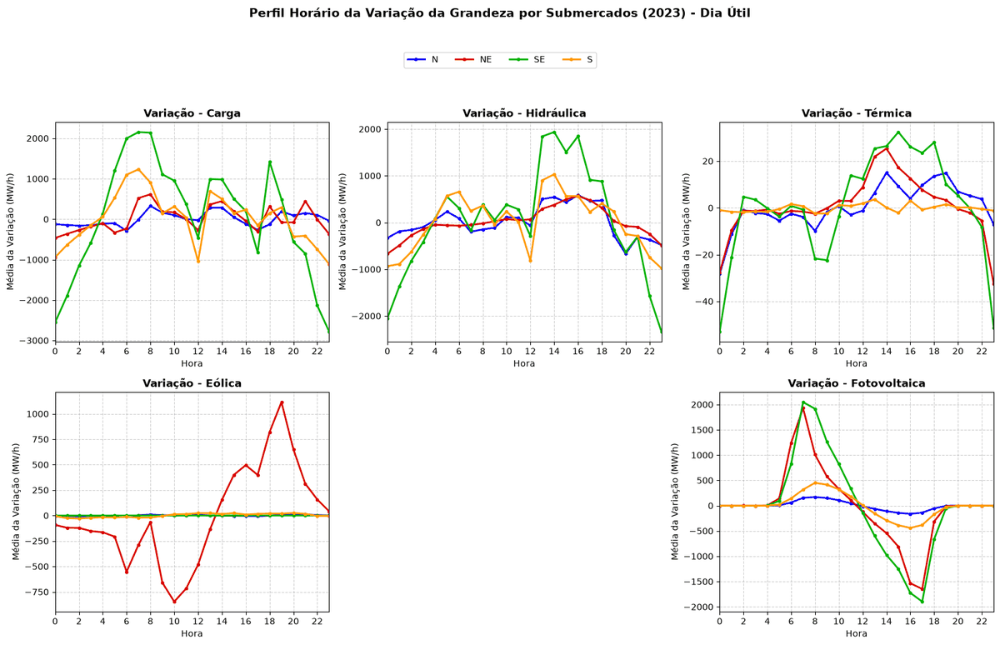

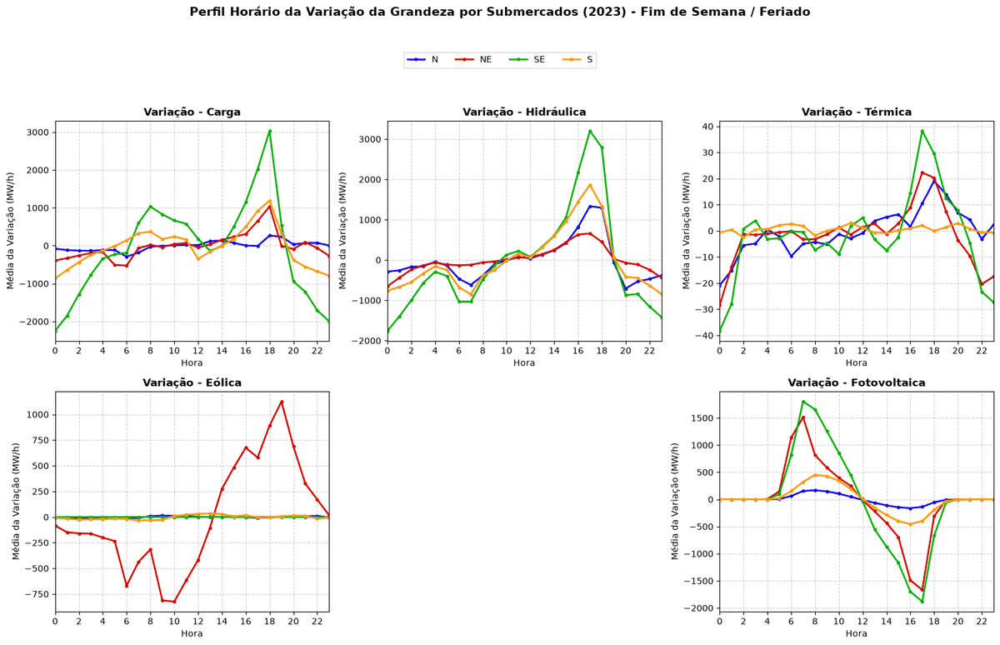

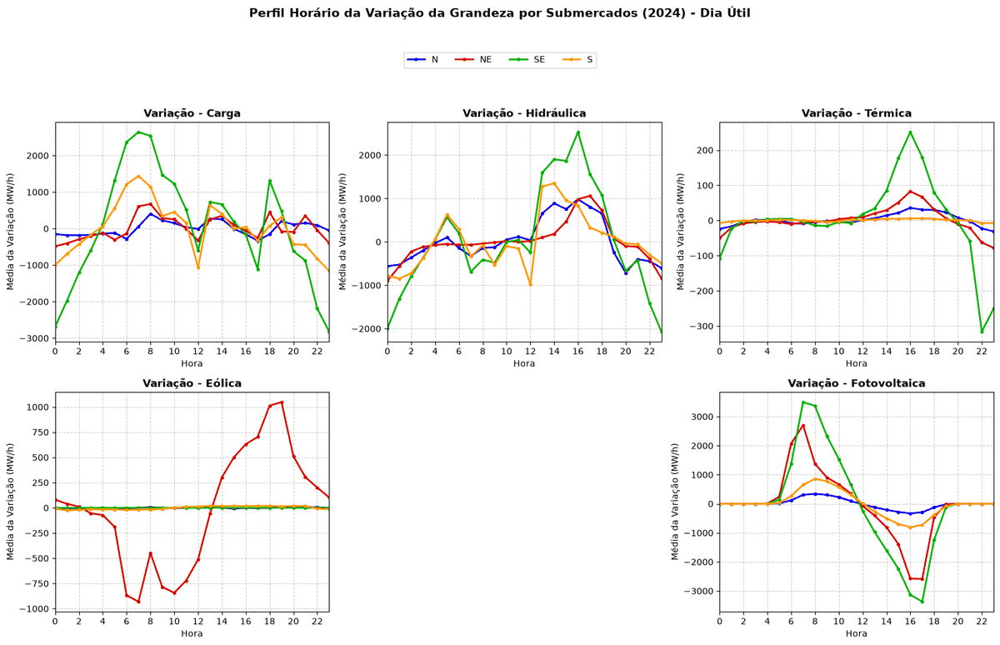

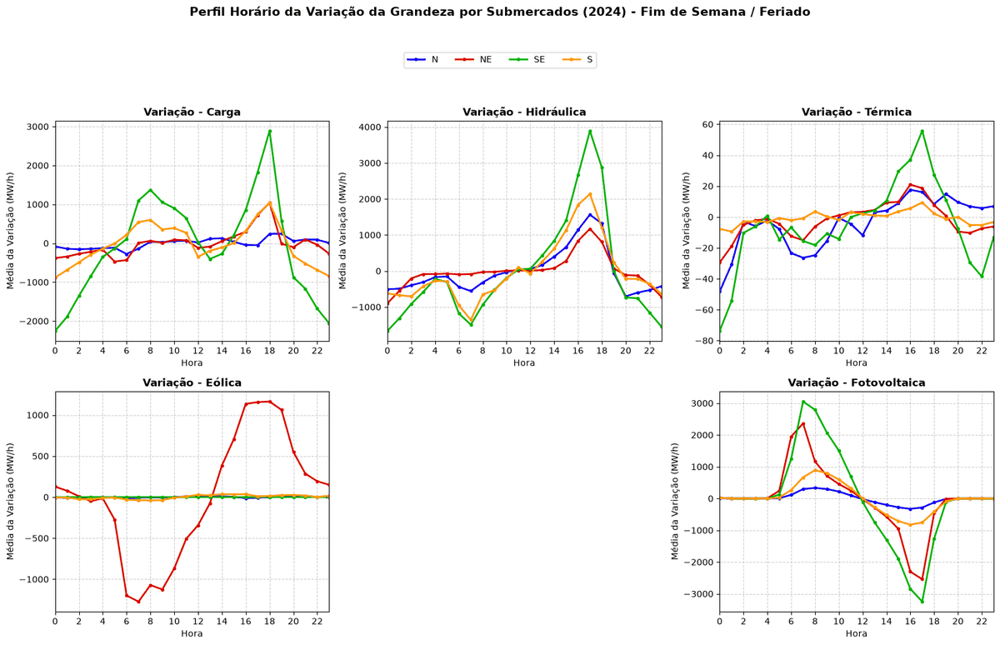

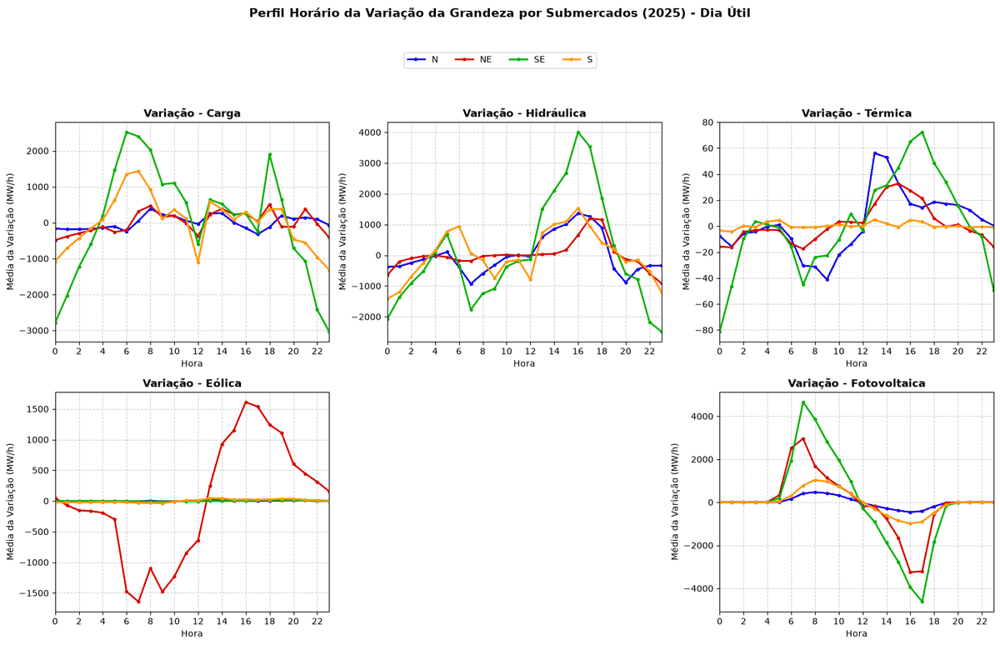

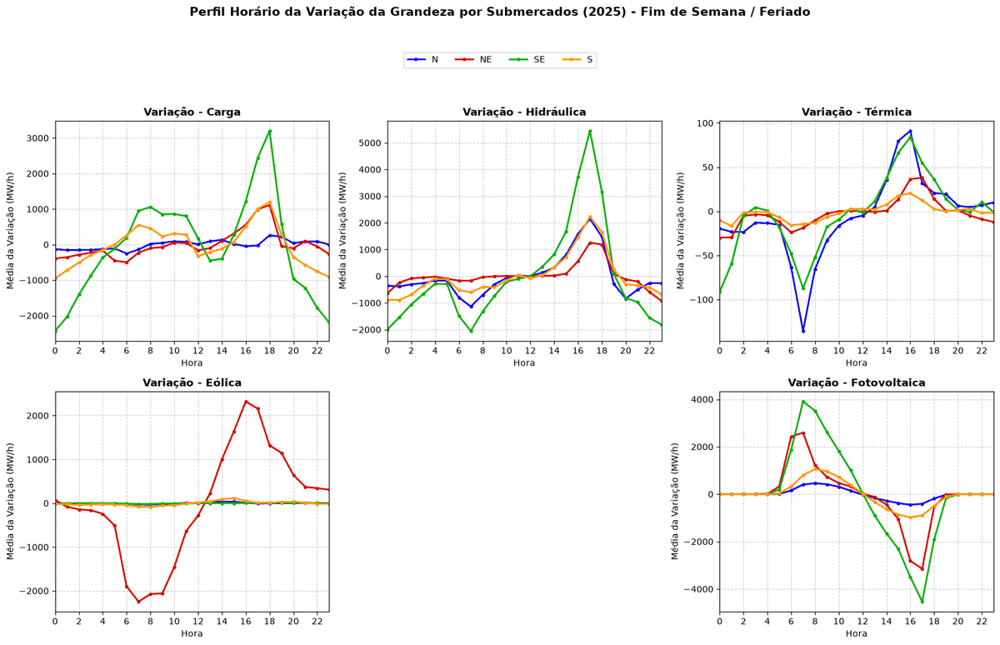

In [17]:
# Script para análise do perfil horário da variação das grandezas por submercado, comparando os anos 2023, 2024 e 2025

lista_consolidada = []
dias_uteis = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira']

for ano, df in dataframes.items():
    df_ano = df.copy()
    
    # Classifica o tipo de dia e extrai a hora
    df_ano['grupo_dia'] = df_ano['tipo_dia'].apply(
        lambda x: 'Dia Útil' if x in dias_uteis else 'Fim de Semana / Feriado'
    )
    df_ano['hora'] = df_ano['din_instante'].dt.hour
    df_ano['ano'] = str(ano) 
    
    lista_consolidada.append(df_ano)

df_total = pd.concat(lista_consolidada, ignore_index=True)

cols_variacao = [
    'var_val_carga',
    'var_val_gerhidraulica',
    'var_val_gertermica',
    'var_val_gereolica',
    'var_val_gersolar'
]

nomes_variacao = [
    'Variação - Carga',
    'Variação - Hidráulica',
    'Variação - Térmica',
    'Variação - Eólica',
    'Variação - Fotovoltaica'
]

posicoes_grid = [
    (0, 0),  # Variação - Carga
    (0, 1),  # Variação - Hidráulica 
    (0, 2),  # Variação - Térmica
    (1, 0),  # Variação - Eólica 
    (1, 2)   # Variação - Fotovoltaica 
]

cores_subs = {
    'N': '#1201fc',   
    'NE': '#d90202',  
    'SE': '#00b100',  
    'S': "#ff9900" 
}

submercados = ['N', 'NE', 'SE', 'S']
tipos_periodo = ['Dia Útil', 'Fim de Semana / Feriado']
anos_alvo = ['2023', '2024', '2025']

# 1. Loops para gerar as figuras por Ano e por Tipo de Período
for ano_str in anos_alvo:
    df_ano_atual = df_total[df_total['ano'] == ano_str]
    
    if df_ano_atual.empty:
        continue
        
    for periodo in tipos_periodo:
        df_periodo = df_ano_atual[df_ano_atual['grupo_dia'] == periodo]
        
        if df_periodo.empty:
            continue
            
        fig = plt.figure(figsize=(16, 10))
        gs = gridspec.GridSpec(nrows=2, ncols=3, figure=fig)
        
        for i, col in enumerate(cols_variacao):
            linha, coluna = posicoes_grid[i]
            ax = fig.add_subplot(gs[linha, coluna])
            
            for sub in submercados:
                df_sub = df_periodo[df_periodo['id_subsistema'] == sub]
                
                if not df_sub.empty:
                    perfil_sub = df_sub.groupby('hora')[col].mean()
                    
                    ax.plot(
                        perfil_sub.index,
                        perfil_sub.values,
                        label=sub,
                        linewidth=2,
                        marker='o',
                        markersize=3,
                        color=cores_subs[sub]
                    )
            
            ax.set_title(f'{nomes_variacao[i]}', fontsize=12, fontweight='bold')
            ax.set_xlabel('Hora', fontsize=10)
            ax.set_ylabel('Média da Variação (MW/h)', fontsize=10)
            
            ax.set_xlim(0, 23)
            ax.set_xticks(range(0, 24, 2))
            
            ax.tick_params(labelbottom=True)
            ax.grid(True, linestyle='--', alpha=0.6)
            
            if i == 0:
                handles, labels = ax.get_legend_handles_labels()

        plt.suptitle(
            f'Perfil Horário da Variação da Grandeza por Submercados ({ano_str}) - {periodo}',
            fontsize=14,
            fontweight='bold',
            y=1.02
        )
        
        fig.legend(handles, labels, loc='lower center',
                    bbox_to_anchor=(0.5, 0.915), ncol=4, fontsize=10, title_fontsize=10)
                                            
        plt.tight_layout(rect=[0, 0, 1, 0.91])
        plt.show()

**5. Análise Estatítica ou Modelo**

**5.1 Análise comparativa da rampa por grandeza no SIN: representação da distribuição pelo gráfico de violino**

C:\Users\SuperFast\AppData\Local\Temp\ipykernel_5144\3212904720.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\SuperFast\AppData\Local\Temp\ipykernel_5144\3212904720.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\SuperFast\AppData\Local\Temp\ipykernel_5144\3212904720.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\SuperFast\AppData\Local\Temp\ipykernel_5144\3212904720.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign t

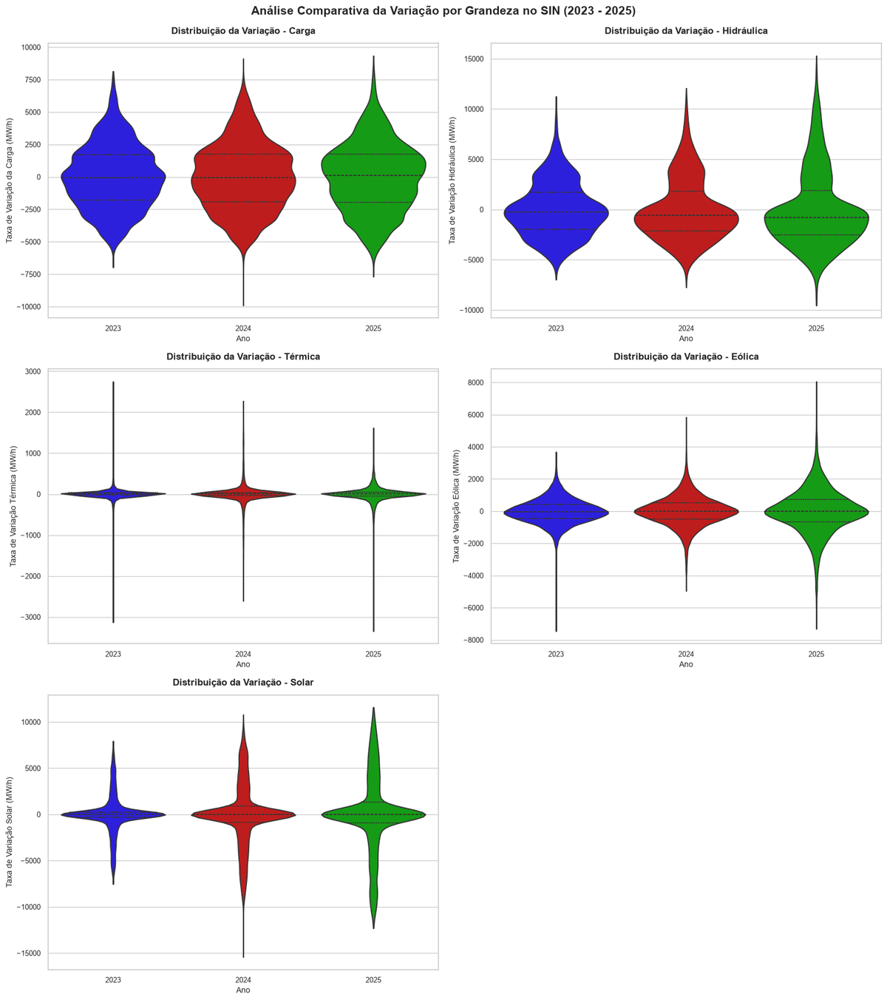

In [18]:
# Script para análise comparativa da rampa por grandeza no SIN (2023 - 2025)

lista_consolidada = []

for ano, df in dataframes.items():
  # Filtra dados do SIN
  df_sin = df[df['id_subsistema'] == 'SIN'].copy()
  df_sin['ano'] = str(ano)
  lista_consolidada.append(df_sin)

df_total = pd.concat(lista_consolidada, ignore_index=True)

df_total['ano'] = df_total['ano'].astype(str)

paleta_anos = {'2023': '#1201fc', '2024': '#d90202', '2025': '#00b100'}

variaveis_estresse = [
    {
        'col': 'var_val_carga',
        'titulo': 'Variação - Carga',
        'ylabel': 'Taxa de Variação da Carga (MW/h)',
    },
    {
        'col': 'var_val_gerhidraulica',
        'titulo': 'Variação - Hidráulica',
        'ylabel': 'Taxa de Variação Hidráulica (MW/h)',
    },
    {
        'col': 'var_val_gertermica',
        'titulo': 'Variação - Térmica',
        'ylabel': 'Taxa de Variação Térmica (MW/h)',
    },
    {
        'col': 'var_val_gereolica',
        'titulo': 'Variação - Eólica',
        'ylabel': 'Taxa de Variação Eólica (MW/h)',
    },
    {
        'col': 'var_val_gersolar',
        'titulo': 'Variação - Solar',
        'ylabel': 'Taxa de Variação Solar (MW/h)',
    },
]

sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for idx, var_info in enumerate(variaveis_estresse):
  ax = axes[idx]

  sns.violinplot(
      data=df_total,
      x='ano',
      y=var_info['col'],
      order=['2023', '2024', '2025'],
      palette=paleta_anos,
      ax=ax,
      inner='quart',
      cut=0,
      linewidth=1.5,
  )

  ax.set_title(
      f'Distribuição da {var_info["titulo"]}',
      fontsize=12,
      fontweight='bold',
      pad=12,
  )
  ax.set_xlabel('Ano', fontsize=10)
  ax.set_ylabel(var_info['ylabel'], fontsize=10)
  ax.tick_params(labelsize=9)

fig.delaxes(axes[5])

plt.suptitle(
    'Análise Comparativa da Variação por Grandeza no SIN (2023 - 2025)',
    fontsize=15,
    fontweight='bold',
    y=0.99,
)

plt.tight_layout()
plt.show()

**5.2 Análise de Correlação de Pearson entre variações da carga e geração no SIN**

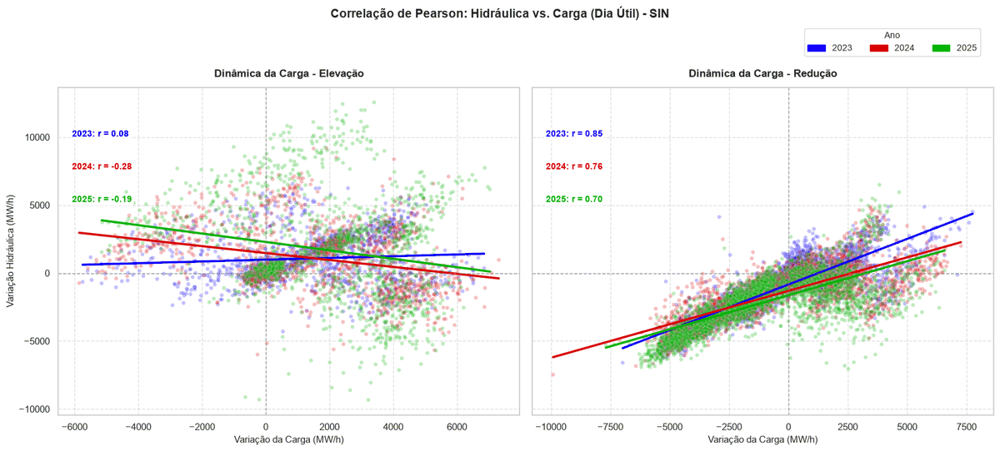

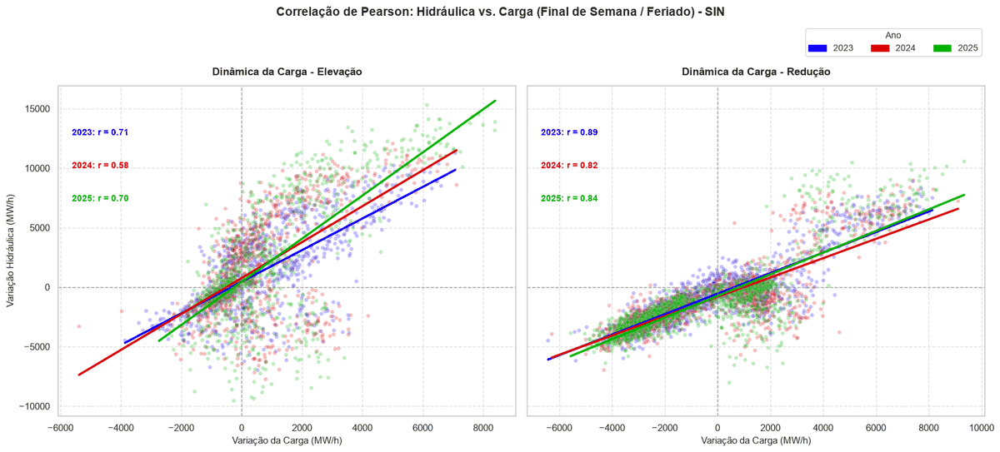

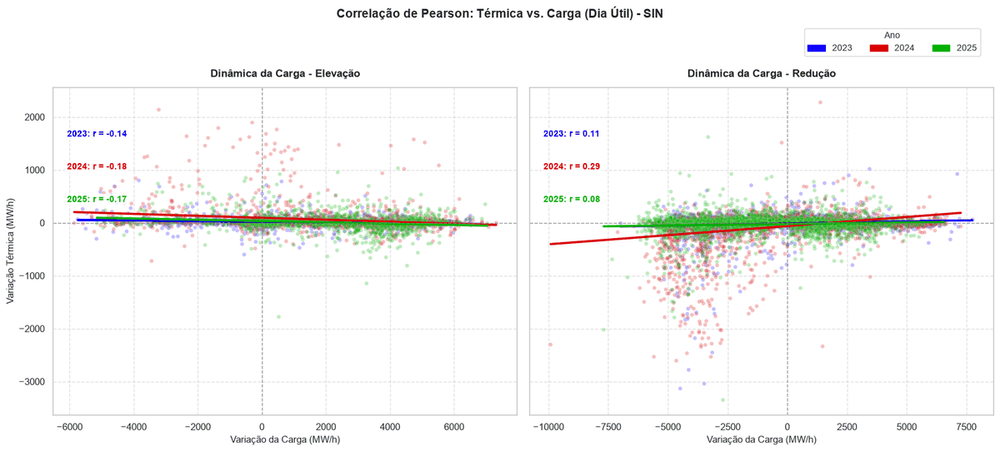

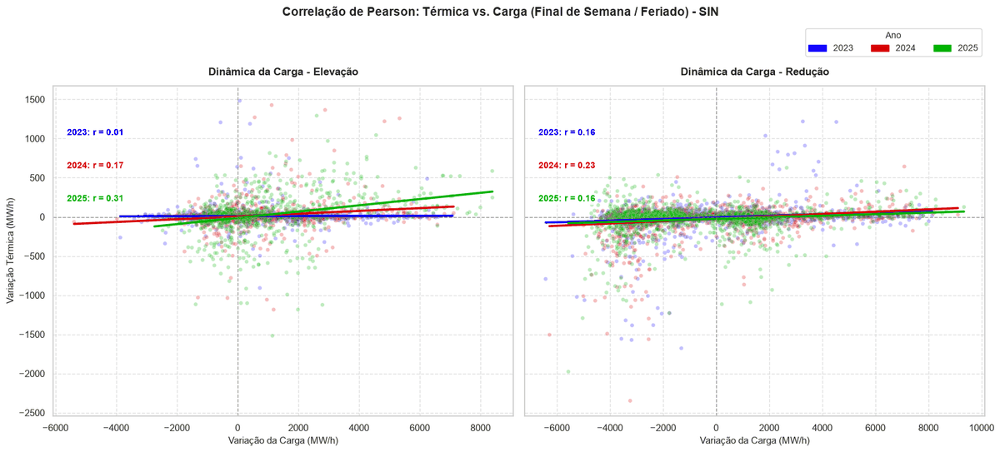

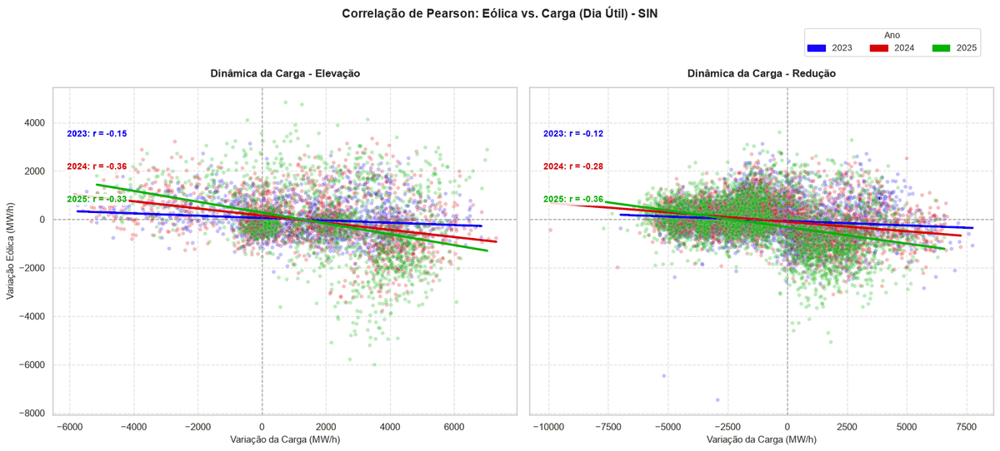

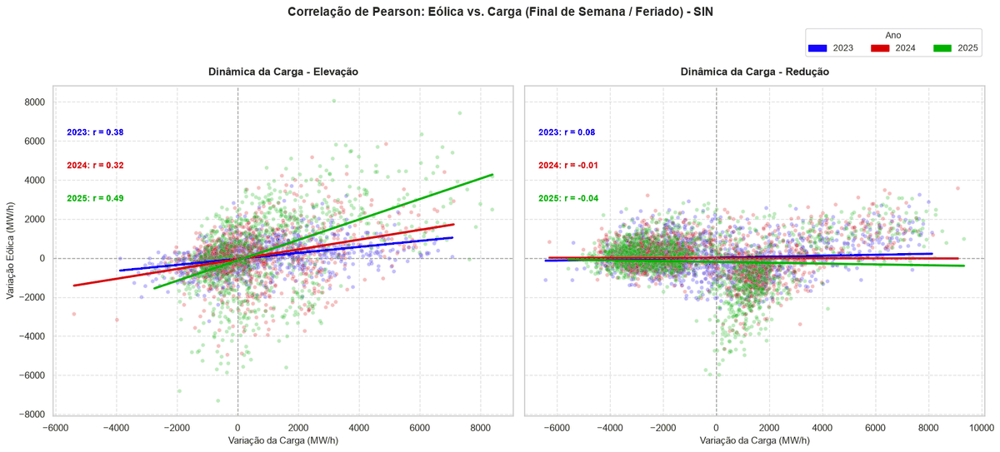

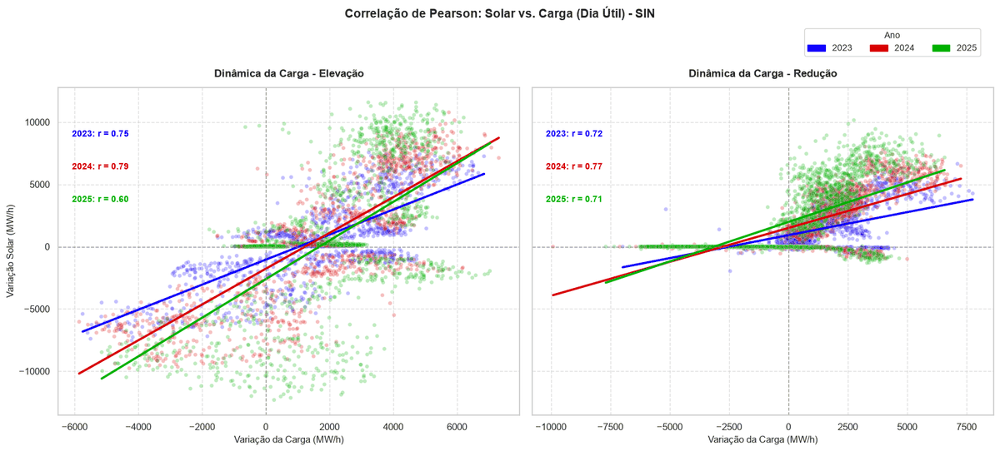

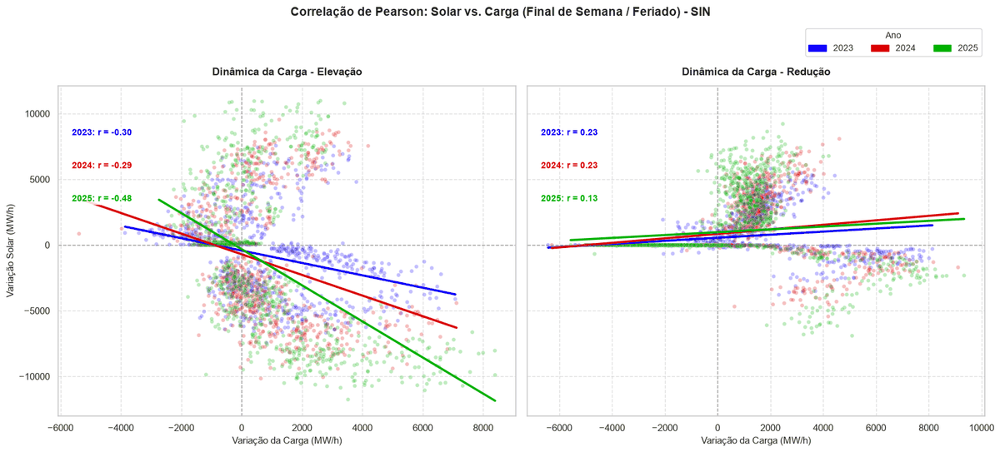

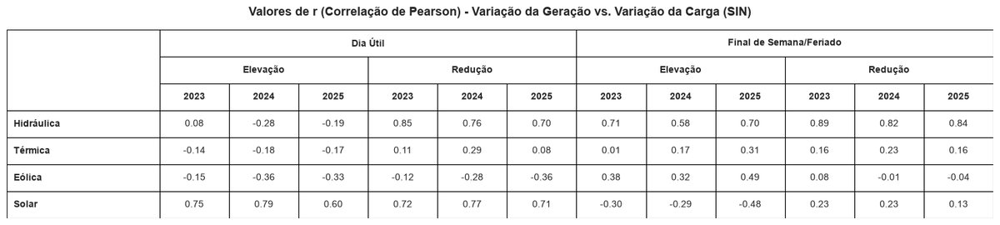

In [19]:
# Script para análise de Correlação de Pearson entre variações de geração e carga no SIN

dias_uteis = [
    'Segunda-feira',
    'Terça-feira',
    'Quarta-feira',
    'Quinta-feira',
    'Sexta-feira',
]
lista_consolidada = []

for ano, df in dataframes.items():
  # Filtra estritamente os dados do SIN
  df_sin = df[df['id_subsistema'] == 'SIN'].copy()

  # Classifica o grupo do dia utilizando a sua coluna 'tipo_dia' e extrai a hora
  df_sin['grupo_dia'] = df_sin['tipo_dia'].apply(
      lambda x: 'Dia Útil' if x in dias_uteis else 'Fim de Semana / Feriado'
  )
  df_sin['hora'] = df_sin['din_instante'].dt.hour
  df_sin['ano'] = str(ano)

  lista_consolidada.append(df_sin)

df_total = pd.concat(lista_consolidada, ignore_index=True)


# 2. Função para classificar as janelas de Elevação e Redução conforme o tipo de dia
def classifica_janela_por_grupo(row):
  grupo = row['grupo_dia']
  hora = row['hora']

  if grupo == 'Dia Útil':
    # --- CARGA DE DIA ÚTIL ---
    # Elevação: 04h-08h, 17h-19h
    if (4 <= hora < 8) or (17 <= hora < 19):
      return 'Dia Útil - Elevação'
    # Redução: 08h-12h, 19h-04h
    elif (8 <= hora < 12) or (hora >= 19 or hora < 4):
      return 'Dia Útil - Redução'
  else:
    # --- CARGA DE FINAL DE SEMANA / FERIADO ---
    # Elevação: 04h-08h, 14h-18h
    if (4 <= hora < 8) or (14 <= hora < 18):
      return 'FDS/Feriado - Elevação'
    # Redução: 08h-12h, 18h-04h
    elif (8 <= hora < 12) or (hora >= 18 or hora < 4):
      return 'FDS/Feriado - Redução'

  return 'Fora das Janelas'


df_total['classificacao'] = df_total.apply(classifica_janela_por_grupo, axis=1)

paleta_anos = {'2023': '#1201fc', '2024': '#d90202', '2025': '#00b100'}

pares_comparacao = [
    {
        'col_y': 'var_val_gerhidraulica',
        'nome': 'Hidráulica vs. Carga',
        'ylabel': 'Variação Hidráulica (MW/h)',
    },
    {
        'col_y': 'var_val_gertermica',
        'nome': 'Térmica vs. Carga',
        'ylabel': 'Variação Térmica (MW/h)',
    },
    {
        'col_y': 'var_val_gereolica',
        'nome': 'Eólica vs. Carga',
        'ylabel': 'Variação Eólica (MW/h)',
    },
    {
        'col_y': 'var_val_gersolar',
        'nome': 'Solar vs. Carga',
        'ylabel': 'Variação Solar (MW/h)',
    },
]

tipos_dia = [
    {
        'titulo_tipo': 'Dia Útil',
        'janelas': ['Dia Útil - Elevação', 'Dia Útil - Redução'],
        'labels_col': ['Elevação', 'Redução'],
    },
    {
        'titulo_tipo': 'Final de Semana / Feriado',
        'janelas': ['FDS/Feriado - Elevação', 'FDS/Feriado - Redução'],
        'labels_col': ['Elevação', 'Redução'],
    },
]

sns.set_theme(style='whitegrid')

resultados_r = []

# 3. Loop para gerar as figuras separadas por par de comparação e tipo de dia
for par in pares_comparacao:
  for tipo in tipos_dia:
    fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

    for coluna_idx, janela_nome in enumerate(tipo['janelas']):
      ax = axes[coluna_idx]
      dados_filtrados = df_total[df_total['classificacao'] == janela_nome]

      sns.scatterplot(
          data=dados_filtrados,
          x='var_val_carga',
          y=par['col_y'],
          hue='ano',
          palette=paleta_anos,
          alpha=0.25,
          s=20,
          ax=ax,
          legend=False,
      )

      y_text_offset = 0.85
      for ano, cor in paleta_anos.items():
        dados_ano = dados_filtrados[dados_filtrados['ano'] == ano]
        if not dados_ano.empty and len(dados_ano) > 1:
          # Regressão linear
          sns.regplot(
              data=dados_ano,
              x='var_val_carga',
              y=par['col_y'],
              color=cor,
              scatter=False,
              ax=ax,
              ci=None,
              line_kws={'linewidth': 2.5},
          )

          r_val = dados_ano['var_val_carga'].corr(
              dados_ano[par['col_y']], method='pearson'
          )

          resultados_r.append({
              'fonte': par['nome'].split(' vs.')[0],
              'classificacao': janela_nome,
              'ano': ano,
              'r': r_val,
          })

          
          texto_r = (
              f'{ano}: r = {r_val:.2f}'
              if not pd.isna(r_val)
              else f'{ano}: r = N/A'
          )
          ax.text(
              0.03,
              y_text_offset,
              texto_r,
              transform=ax.transAxes,
              fontsize=10,
              fontweight='bold',
              color=cor,
              bbox=dict(
                  boxstyle='round,pad=0.2',
                  facecolor='white',
                  alpha=0.85,
                  edgecolor='none',
              ),
          )
          y_text_offset -= 0.10

      label_janela = tipo['labels_col'][coluna_idx]
      ax.set_title(
          f'Dinâmica da Carga - {label_janela}',
          fontsize=12,
          fontweight='bold',
          pad=12,
      )
      ax.set_xlabel('Variação da Carga (MW/h)', fontsize=11)
      ax.set_ylabel(par['ylabel'], fontsize=11)

      ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
      ax.axvline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
      ax.grid(True, linestyle='--', alpha=0.6)

    handles = [Patch(color=cor, label=ano) for ano, cor in paleta_anos.items()]
    fig.legend(
        handles,
        list(paleta_anos.keys()),
        title='Ano',
        loc='upper right',
        bbox_to_anchor=(0.98, 0.98),
        fontsize=10,
        title_fontsize=10,
        ncol=3,
    )

    plt.suptitle(
        f'Correlação de Pearson: {par["nome"]} ({tipo["titulo_tipo"]}) - SIN',
        fontsize=14,
        fontweight='bold',
        y=1.02,
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# 4. Tabela consolidada dos valores de r (Correlação de Pearson)
from matplotlib.patches import Rectangle

r_lookup = {
    (res['fonte'], res['classificacao'], res['ano']): res['r']
    for res in resultados_r
}

fontes_tabela = ['Hidráulica', 'Térmica', 'Eólica', 'Solar']
anos_tabela = list(paleta_anos.keys())
grupos_tabela = [
    ('Dia Útil', 'Dia Útil'),
    ('Final de Semana/Feriado', 'FDS/Feriado'),
]
janelas_tabela = ['Elevação', 'Redução']

largura_rotulo = 2.2
cols_por_grupo = len(janelas_tabela) * len(anos_tabela)
total_largura = largura_rotulo + len(grupos_tabela) * cols_por_grupo
n_linhas = 3 + len(fontes_tabela)

fig, ax = plt.subplots(figsize=(15, 3.5))
ax.set_xlim(0, total_largura)
ax.set_ylim(0, n_linhas)
ax.invert_yaxis()
ax.axis('off')


def desenha_celula(x, y, w, h, texto='', bold=False, fontsize=10, ha='center'):
  ax.add_patch(
      Rectangle((x, y), w, h, fill=False, edgecolor='black', linewidth=0.8)
  )
  if texto:
    x_texto = x + w / 2 if ha == 'center' else x + 0.1
    ax.text(
        x_texto,
        y + h / 2,
        texto,
        ha=ha,
        va='center',
        fontsize=fontsize,
        fontweight='bold' if bold else 'normal',
    )


desenha_celula(0, 0, largura_rotulo, 3)
for g_idx, (titulo_grupo, _) in enumerate(grupos_tabela):
  x_grupo = largura_rotulo + g_idx * cols_por_grupo
  desenha_celula(x_grupo, 0, cols_por_grupo, 1, titulo_grupo, bold=True)
  for j_idx, janela in enumerate(janelas_tabela):
    x_janela = x_grupo + j_idx * len(anos_tabela)
    desenha_celula(x_janela, 1, len(anos_tabela), 1, janela, bold=True)
    for a_idx, ano_tab in enumerate(anos_tabela):
      desenha_celula(x_janela + a_idx, 2, 1, 1, ano_tab, bold=True)

for f_idx, fonte in enumerate(fontes_tabela):
  y_linha = 3 + f_idx
  desenha_celula(0, y_linha, largura_rotulo, 1, fonte, bold=True, ha='left')
  x_col = largura_rotulo
  for _, prefixo_grupo in grupos_tabela:
    for janela in janelas_tabela:
      for ano_tab in anos_tabela:
        r = r_lookup.get((fonte, prefixo_grupo + ' - ' + janela, ano_tab))
        texto = f'{r:.2f}' if r is not None and not pd.isna(r) else 'N/A'
        desenha_celula(x_col, y_linha, 1, 1, texto)
        x_col += 1

ax.set_title(
    'Valores de r (Correlação de Pearson) - Variação da Geração vs. Variação'
    ' da Carga (SIN)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.tight_layout()
plt.show()

**5.3 Análise de Correlação de Pearson entre variações de geração solar e outras fontes no SIN**

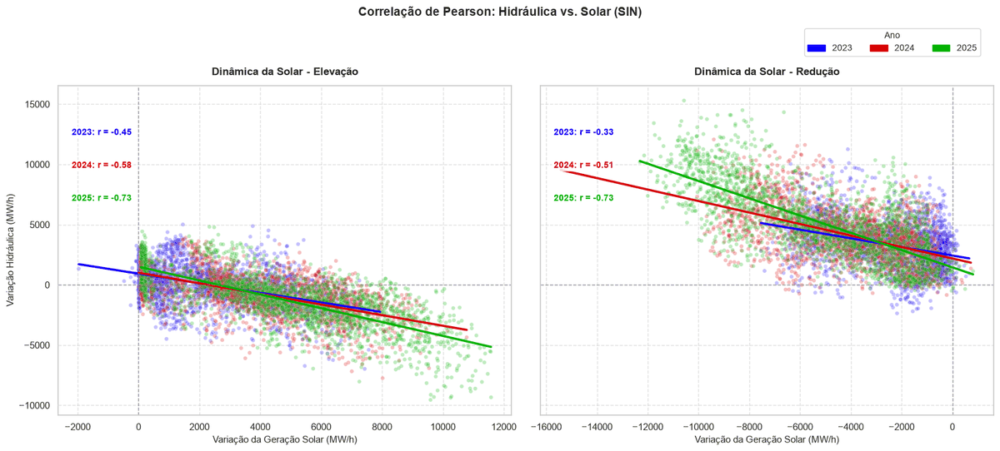

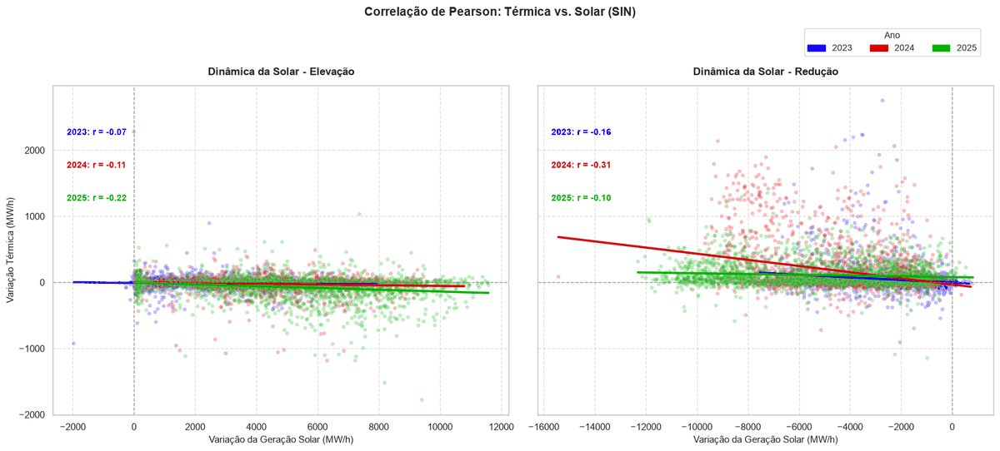

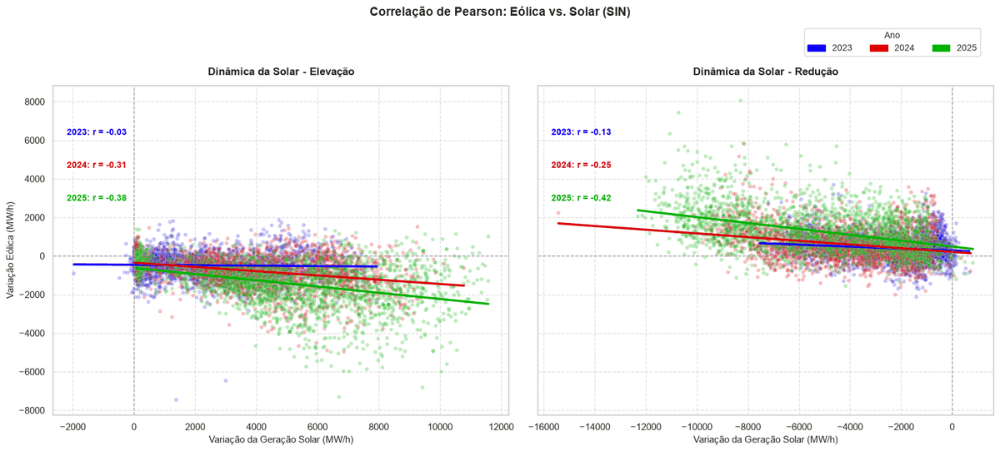

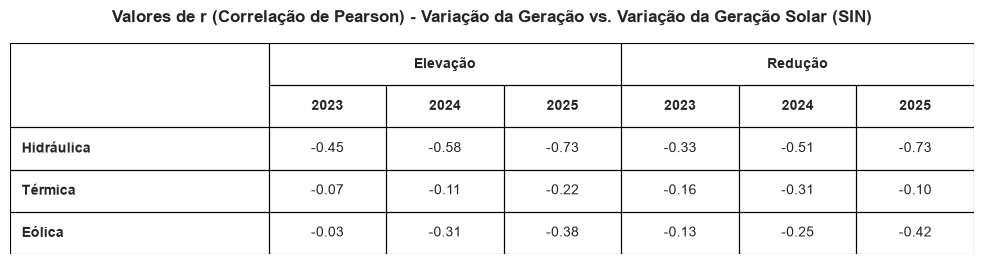

In [20]:
# Script para análise da correlação entre a geração solar e outras fontes no SIN, para os anos de 2023, 2024 e 2025

lista_consolidada = []

for ano, df in dataframes.items():
  df_sin = df[df['id_subsistema'] == 'SIN'].copy()
  df_sin['hora'] = df_sin['din_instante'].dt.hour
  df_sin['ano'] = str(ano)
  lista_consolidada.append(df_sin)

df_total = pd.concat(lista_consolidada, ignore_index=True)


# 2. Função para classificar os dados nas duas janelas operativas
def classifica_janela(hora):
  if 5 <= hora <= 10:
    return 'Dinâmica da Solar - Elevação'
  elif 13 <= hora <= 18:
    return 'Dinâmica da Solar - Redução'
  return 'Fora das Janelas'


df_total['janela'] = df_total['hora'].apply(classifica_janela)
df_foco = df_total[df_total['janela'] != 'Fora das Janelas']

paleta_anos = {'2023': '#1201fc', '2024': '#d90202', '2025': '#00b100'}
janelas_disponiveis = ['Dinâmica da Solar - Elevação', 'Dinâmica da Solar - Redução']

# Pares de grandezas a serem comparados (cada um gerará sua própria figura isolada)
pares_comparacao = [
    {
        'col_y': 'var_val_gerhidraulica',
        'nome': 'Hidráulica vs. Solar',
        'ylabel': 'Variação Hidráulica (MW/h)',
        'filename': 'dispersao_hidro_solar.png',
    },
    {
        'col_y': 'var_val_gertermica',
        'nome': 'Térmica vs. Solar',
        'ylabel': 'Variação Térmica (MW/h)',
        'filename': 'dispersao_termica_solar.png',
    },
    {
        'col_y': 'var_val_gereolica',
        'nome': 'Eólica vs. Solar',
        'ylabel': 'Variação Eólica (MW/h)',
        'filename': 'dispersao_eolica_solar.png',
    },
]

sns.set_theme(style='whitegrid')

resultados_r = []

# 3. Loop para gerar uma figura separada para cada par de comparação
for par in pares_comparacao:
  fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

  for coluna_idx, janela in enumerate(janelas_disponiveis):
    ax = axes[coluna_idx]
    dados_filtrados = df_foco[df_foco['janela'] == janela]

    sns.scatterplot(
        data=dados_filtrados,
        x='var_val_gersolar',
        y=par['col_y'],
        hue='ano',
        palette=paleta_anos,
        alpha=0.25,
        s=20,
        ax=ax,
        legend=False,
    )

    y_text_offset = 0.85
    for ano, cor in paleta_anos.items():
      dados_ano = dados_filtrados[dados_filtrados['ano'] == ano]
      if not dados_ano.empty:
        sns.regplot(
            data=dados_ano,
            x='var_val_gersolar',
            y=par['col_y'],
            color=cor,
            scatter=False,
            ax=ax,
            ci=None,
            line_kws={'linewidth': 2.5},
        )

        r_val = dados_ano['var_val_gersolar'].corr(
            dados_ano[par['col_y']], method='pearson'
        )

        resultados_r.append({
            'fonte': par['nome'].split(' vs.')[0],
            'janela': janela,
            'ano': ano,
            'r': r_val,
        })

        ax.text(
            0.03,
            y_text_offset,
            f'{ano}: r = {r_val:.2f}',
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            color=cor,
            bbox=dict(
                boxstyle='round,pad=0.2',
                facecolor='white',
                alpha=0.85,
                edgecolor='none',
            ),
        )
        y_text_offset -= 0.10

    ax.set_title(f'{janela}', fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Variação da Geração Solar (MW/h)', fontsize=11)
    ax.set_ylabel(par['ylabel'], fontsize=11)

    ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
    ax.grid(True, linestyle='--', alpha=0.6)

  handles = [Patch(color=cor, label=ano) for ano, cor in paleta_anos.items()]
  fig.legend(
      handles,
      list(paleta_anos.keys()),
      title='Ano',
      loc='upper right',
      bbox_to_anchor=(0.98, 0.98),
      fontsize=10,
      title_fontsize=10,
      ncol=3,
  )

  plt.suptitle(
      f'Correlação de Pearson: {par["nome"]} (SIN)',
      fontsize=14,
      fontweight='bold',
      y=1.02,
  )

  plt.tight_layout(rect=[0, 0, 1, 0.96])
  plt.show()


r_lookup = {
    (res['fonte'], res['janela'], res['ano']): res['r']
    for res in resultados_r
}

fontes_tabela = ['Hidráulica', 'Térmica', 'Eólica']
anos_tabela = list(paleta_anos.keys())
janelas_tabela = [
    ('Elevação', 'Dinâmica da Solar - Elevação'),
    ('Redução', 'Dinâmica da Solar - Redução'),
]

largura_rotulo = 2.2
total_largura = largura_rotulo + len(janelas_tabela) * len(anos_tabela)
n_linhas = 2 + len(fontes_tabela)

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.set_xlim(0, total_largura)
ax.set_ylim(0, n_linhas)
ax.invert_yaxis()
ax.axis('off')


def desenha_celula(x, y, w, h, texto='', bold=False, fontsize=10, ha='center'):
  ax.add_patch(
      Rectangle((x, y), w, h, fill=False, edgecolor='black', linewidth=0.8)
  )
  if texto:
    x_texto = x + w / 2 if ha == 'center' else x + 0.1
    ax.text(
        x_texto,
        y + h / 2,
        texto,
        ha=ha,
        va='center',
        fontsize=fontsize,
        fontweight='bold' if bold else 'normal',
    )


desenha_celula(0, 0, largura_rotulo, 2)
for j_idx, (titulo_janela, _) in enumerate(janelas_tabela):
  x_janela = largura_rotulo + j_idx * len(anos_tabela)
  desenha_celula(x_janela, 0, len(anos_tabela), 1, titulo_janela, bold=True)
  for a_idx, ano_tab in enumerate(anos_tabela):
    desenha_celula(x_janela + a_idx, 1, 1, 1, ano_tab, bold=True)

for f_idx, fonte in enumerate(fontes_tabela):
  y_linha = 2 + f_idx
  desenha_celula(0, y_linha, largura_rotulo, 1, fonte, bold=True, ha='left')
  x_col = largura_rotulo
  for _, nome_janela in janelas_tabela:
    for ano_tab in anos_tabela:
      r = r_lookup.get((fonte, nome_janela, ano_tab))
      texto = f'{r:.2f}' if r is not None and not pd.isna(r) else 'N/A'
      desenha_celula(x_col, y_linha, 1, 1, texto)
      x_col += 1

ax.set_title(
    'Valores de r (Correlação de Pearson) - Variação da Geração vs. Variação'
    ' da Geração Solar (SIN)',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.tight_layout()
plt.show()


**5.4 Análise de Correlação de Pearson entre variações da carga e geração para os submercados (N, NE, S e SE)**

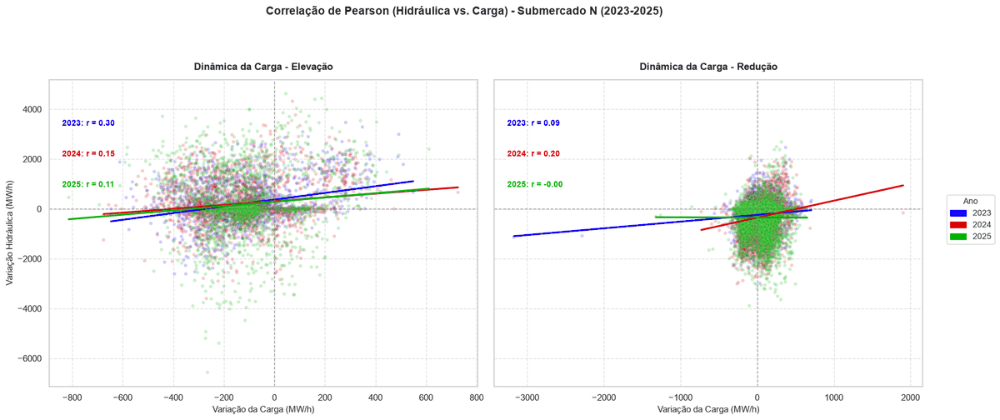

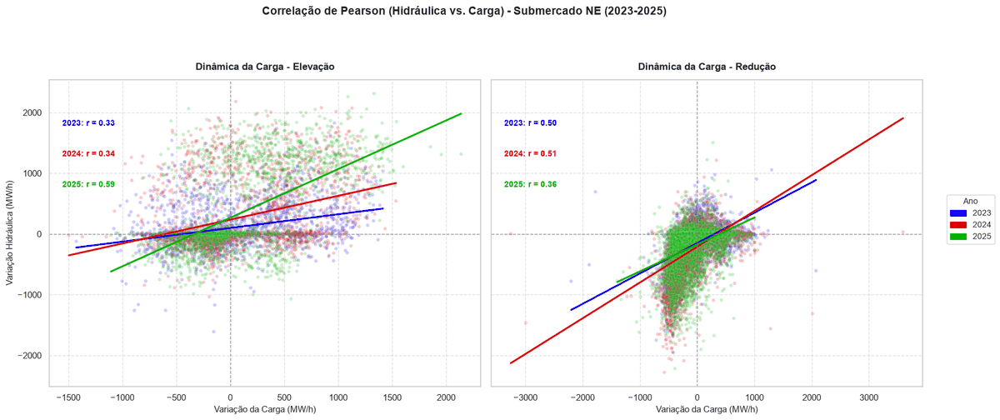

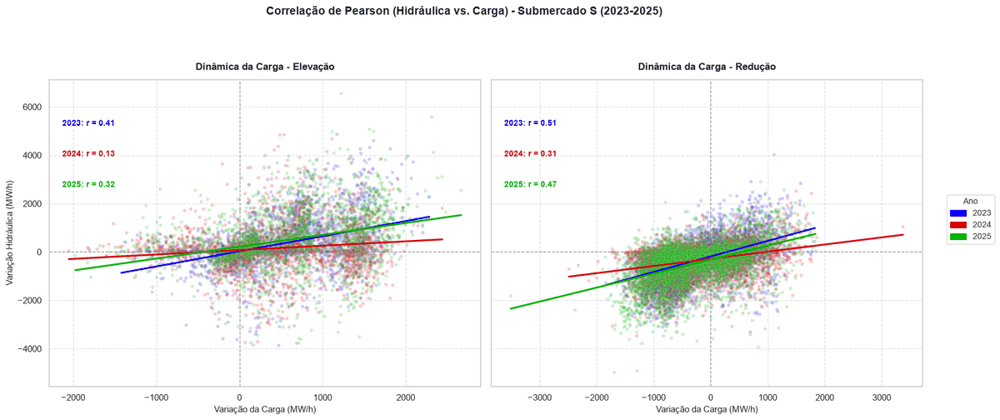

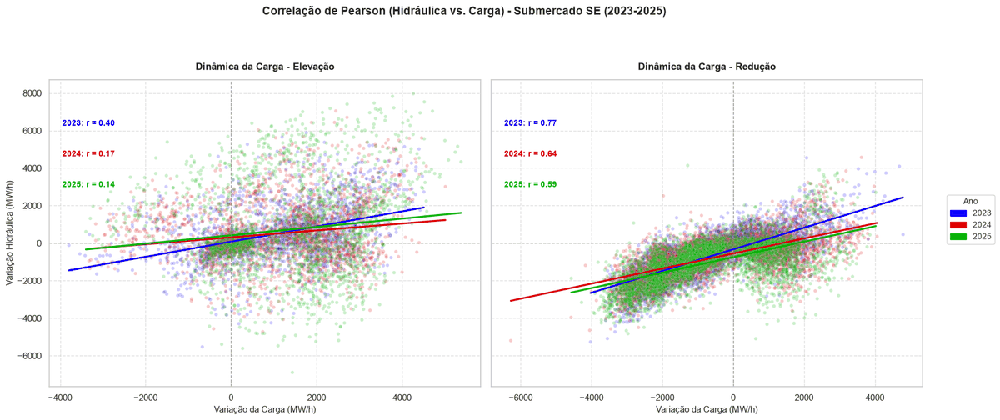

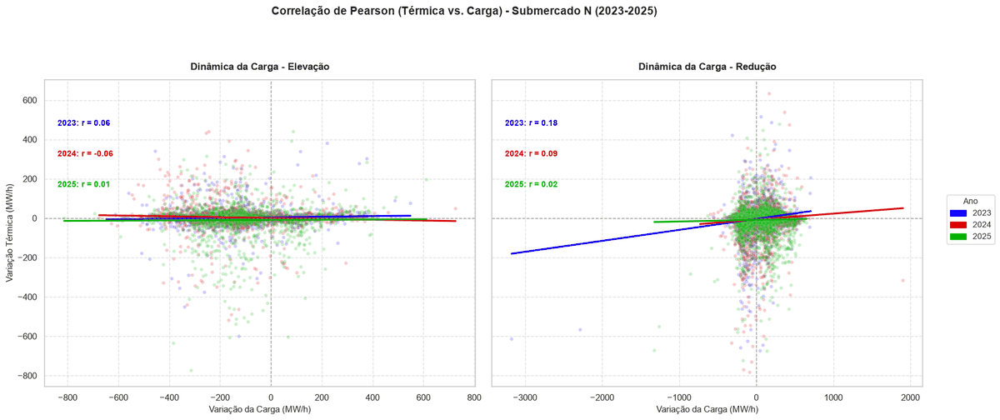

...

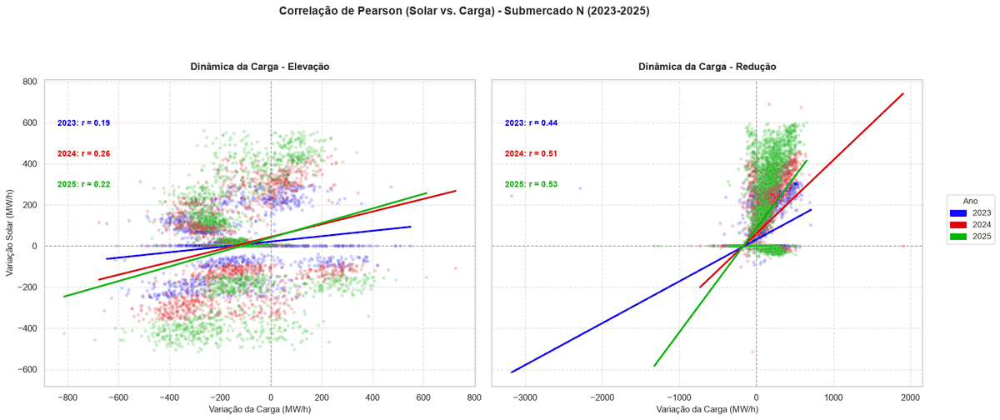

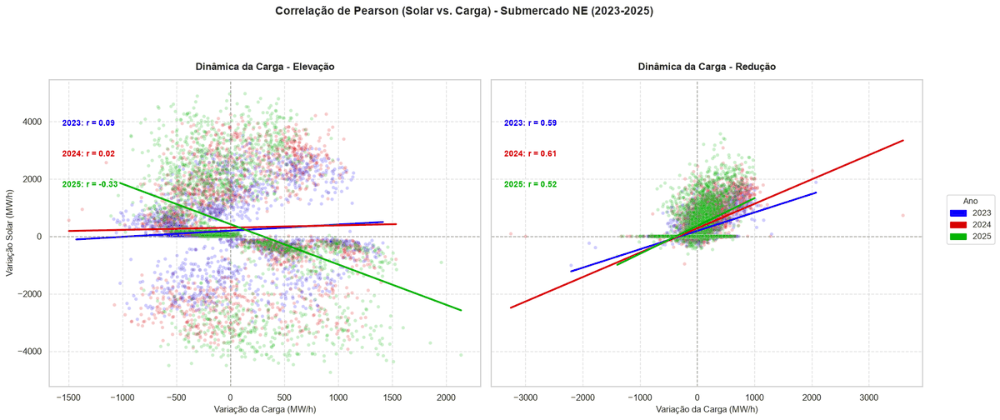

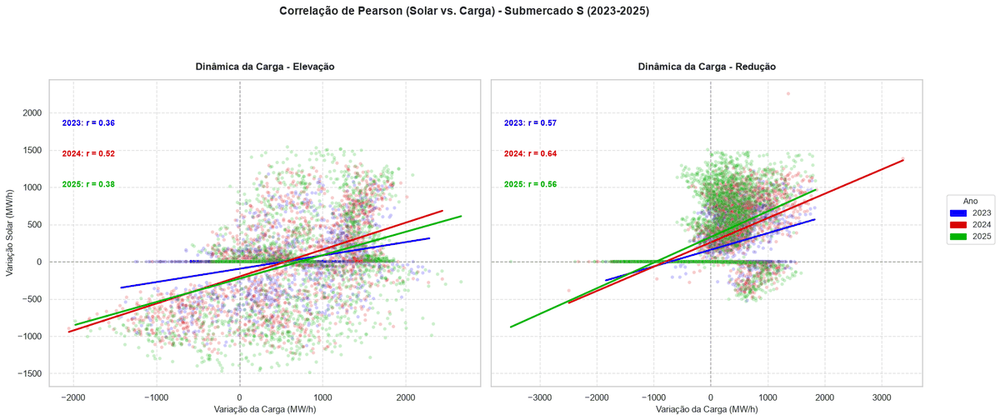

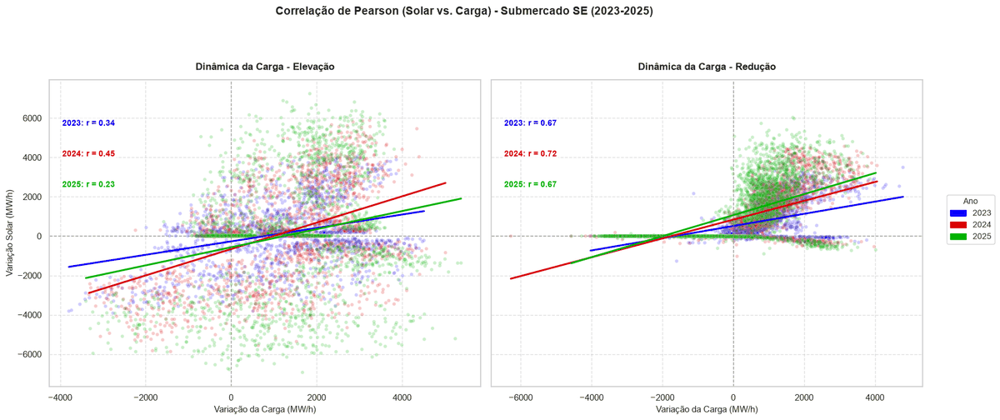

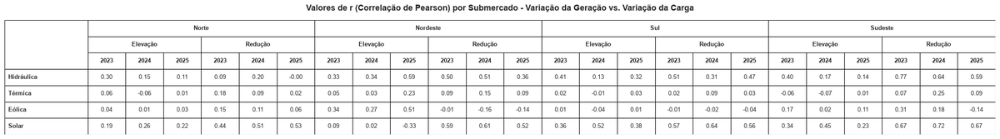

In [21]:
# Script para análise da correlação entre a carga e outras fontes (hidráulica, térmica e eólica) nos submercados SE, S, NE e N para os anos de 2023, 2024 e 2025.

lista_consolidada = []

for ano, df in dataframes.items():
  if str(ano) in ['2023', '2024', '2025']:
    df_sub = df[df['id_subsistema'].isin(['SE', 'S', 'NE', 'N'])].copy()
    df_sub['hora'] = df_sub['din_instante'].dt.hour
    df_sub['ano'] = str(ano)
    lista_consolidada.append(df_sub)

if not lista_consolidada:
  raise ValueError(
      'Nenhum dado encontrado para os anos e submercados especificados.'
  )

df_total = pd.concat(lista_consolidada, ignore_index=True)


# 2. Função para classificar os dados nas janelas de Subida e Descida da Carga
def classifica_janela_carga(hora):
  if (4 <= hora < 8) or (17 <= hora < 19):
    return 'Dinâmica da Carga - Elevação'
  elif (8 <= hora < 12) or (hora >= 19 or hora < 4):
    return 'Dinâmica da Carga - Redução'
  return 'Fora das Janelas'


df_total['janela'] = df_total['hora'].apply(classifica_janela_carga)
df_foco = df_total[df_total['janela'] != 'Fora das Janelas']

submercados = sorted(df_foco['id_subsistema'].unique())
janelas_disponiveis = ['Dinâmica da Carga - Elevação', 'Dinâmica da Carga - Redução']

pares_comparacao = [
    {
        'col_y': 'var_val_gerhidraulica',
        'nome': 'Hidráulica vs. Carga',
        'ylabel': 'Variação Hidráulica (MW/h)',
    },
    {
        'col_y': 'var_val_gertermica',
        'nome': 'Térmica vs. Carga',
        'ylabel': 'Variação Térmica (MW/h)',
    },
    {
        'col_y': 'var_val_gereolica',
        'nome': 'Eólica vs. Carga',
        'ylabel': 'Variação Eólica (MW/h)',
    },
    {
        'col_y': 'var_val_gersolar',
        'nome': 'Solar vs. Carga',
        'ylabel': 'Variação Solar (MW/h)',
    },
]

paleta_anos = {'2023': '#1201fc', '2024': '#d90202', '2025': '#00b100'}
sns.set_theme(style='whitegrid')

resultados_r = []

# 3. Loop por Submercado e por Par de Comparação
for par in pares_comparacao:
  for sub in submercados:
    df_sub = df_foco[df_foco['id_subsistema'] == sub]

    fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

    for coluna_idx, janela in enumerate(janelas_disponiveis):
      ax = axes[coluna_idx]
      dados_janela = df_sub[df_sub['janela'] == janela]

      sns.scatterplot(
          data=dados_janela,
          x='var_val_carga',
          y=par['col_y'],
          hue='ano',
          palette=paleta_anos,
          alpha=0.20,
          s=18,
          ax=ax,
          legend=False,
      )

      y_text_offset = 0.85
      for ano, cor in paleta_anos.items():
        dados_ano = dados_janela[dados_janela['ano'] == ano]
        if not dados_ano.empty:
          sns.regplot(
              data=dados_ano,
              x='var_val_carga',
              y=par['col_y'],
              color=cor,
              scatter=False,
              ax=ax,
              ci=None,
              line_kws={'linewidth': 2.2},
          )

          r_val = dados_ano['var_val_carga'].corr(
              dados_ano[par['col_y']], method='pearson'
          )

          resultados_r.append({
              'fonte': par['nome'].split(' vs.')[0],
              'submercado': sub,
              'janela': janela,
              'ano': ano,
              'r': r_val,
          })
          ax.text(
              0.03,
              y_text_offset,
              f'{ano}: r = {r_val:.2f}'
              if not pd.isna(r_val)
              else f'{ano}: r = N/A',
              transform=ax.transAxes,
              fontsize=10,
              fontweight='bold',
              color=cor,
              bbox=dict(
                  boxstyle='round,pad=0.2',
                  facecolor='white',
                  alpha=0.85,
                  edgecolor='none',
              ),
          )
          y_text_offset -= 0.10

      ax.set_title(f'{janela}', fontsize=12, fontweight='bold', pad=12)
      ax.set_xlabel('Variação da Carga (MW/h)', fontsize=11)
      ax.set_ylabel(par['ylabel'], fontsize=11)
      ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
      ax.axvline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
      ax.grid(True, linestyle='--', alpha=0.6)


    handles = [Patch(color=cor, label=ano) for ano, cor in paleta_anos.items()]
    fig.legend(
        handles,
        list(paleta_anos.keys()),
        title='Ano',
        loc='center left',
        bbox_to_anchor=(1.01, 0.5),
        fontsize=10,
        title_fontsize=10,
    )

    plt.suptitle(
        f'Correlação de Pearson ({par["nome"]}) - Submercado {sub} (2023-2025)',
        fontsize=14,
        fontweight='bold',
        y=1.02,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# 4. Tabela consolidada dos valores de r (Correlação de Pearson)
from matplotlib.patches import Rectangle

r_lookup = {
    (res['fonte'], res['submercado'], res['janela'], res['ano']): res['r']
    for res in resultados_r
}

fontes_tabela = ['Hidráulica', 'Térmica', 'Eólica', 'Solar']
anos_tabela = list(paleta_anos.keys())
submercados_tabela = [
    ('Norte', 'N'),
    ('Nordeste', 'NE'),
    ('Sul', 'S'),
    ('Sudeste', 'SE'),
]
janelas_tabela = [
    ('Elevação', 'Dinâmica da Carga - Elevação'),
    ('Redução', 'Dinâmica da Carga - Redução'),
]

largura_rotulo = 2.2
cols_por_sub = len(janelas_tabela) * len(anos_tabela)
total_largura = largura_rotulo + len(submercados_tabela) * cols_por_sub
n_linhas = 3 + len(fontes_tabela)

fig, ax = plt.subplots(figsize=(22, 3.2))
ax.set_xlim(0, total_largura)
ax.set_ylim(0, n_linhas)
ax.invert_yaxis()
ax.axis('off')


def desenha_celula(x, y, w, h, texto='', bold=False, fontsize=9, ha='center'):
  ax.add_patch(
      Rectangle((x, y), w, h, fill=False, edgecolor='black', linewidth=0.8)
  )
  if texto:
    x_texto = x + w / 2 if ha == 'center' else x + 0.1
    ax.text(
        x_texto,
        y + h / 2,
        texto,
        ha=ha,
        va='center',
        fontsize=fontsize,
        fontweight='bold' if bold else 'normal',
    )


desenha_celula(0, 0, largura_rotulo, 3)
for s_idx, (titulo_sub, _) in enumerate(submercados_tabela):
  x_sub = largura_rotulo + s_idx * cols_por_sub
  desenha_celula(x_sub, 0, cols_por_sub, 1, titulo_sub, bold=True)
  for j_idx, (titulo_janela, _) in enumerate(janelas_tabela):
    x_janela = x_sub + j_idx * len(anos_tabela)
    desenha_celula(x_janela, 1, len(anos_tabela), 1, titulo_janela, bold=True)
    for a_idx, ano_tab in enumerate(anos_tabela):
      desenha_celula(x_janela + a_idx, 2, 1, 1, ano_tab, bold=True)

# Linhas de dados (uma por fonte)
for f_idx, fonte in enumerate(fontes_tabela):
  y_linha = 3 + f_idx
  desenha_celula(0, y_linha, largura_rotulo, 1, fonte, bold=True, ha='left')
  x_col = largura_rotulo
  for _, cod_sub in submercados_tabela:
    for _, nome_janela in janelas_tabela:
      for ano_tab in anos_tabela:
        r = r_lookup.get((fonte, cod_sub, nome_janela, ano_tab))
        texto = f'{r:.2f}' if r is not None and not pd.isna(r) else 'N/A'
        desenha_celula(x_col, y_linha, 1, 1, texto)
        x_col += 1

ax.set_title(
    'Valores de r (Correlação de Pearson) por Submercado - Variação da'
    ' Geração vs. Variação da Carga',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.tight_layout()
plt.show()


**5.5 Análise de Correlação de Pearson entre variações de geração solar e outras fontes para os submercados (N, NE, S e SE)**

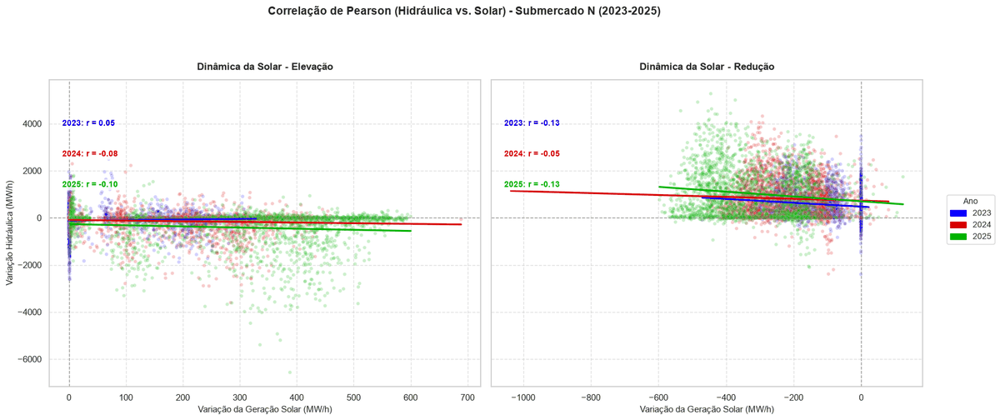

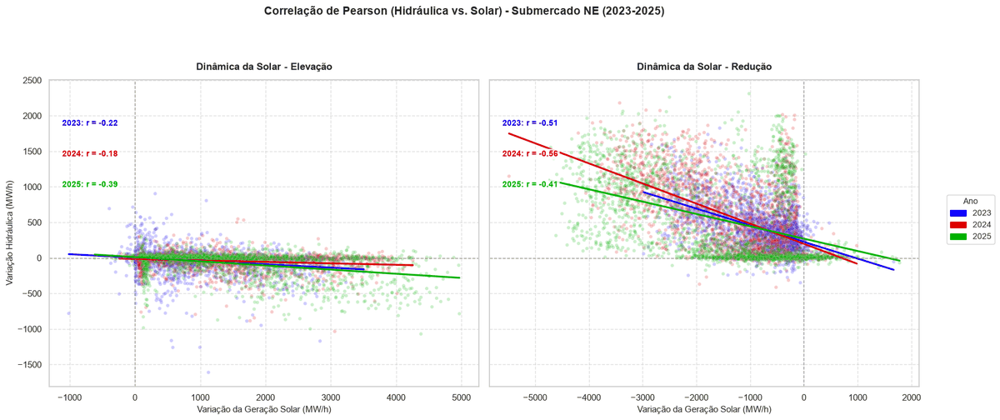

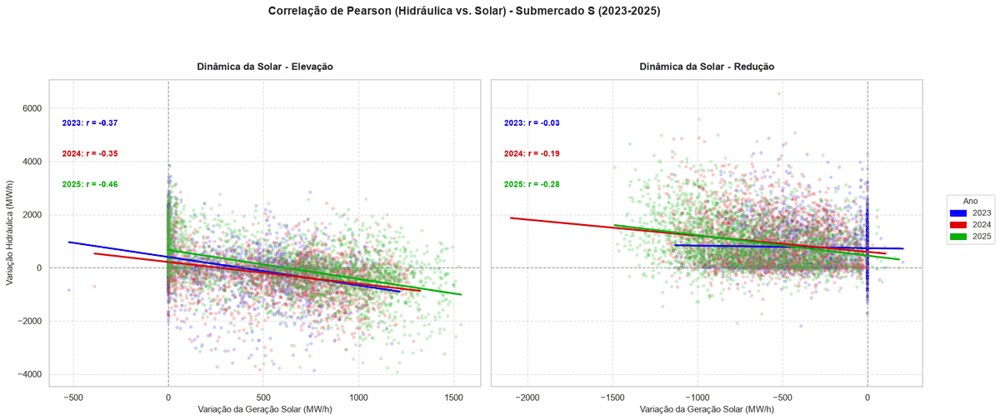

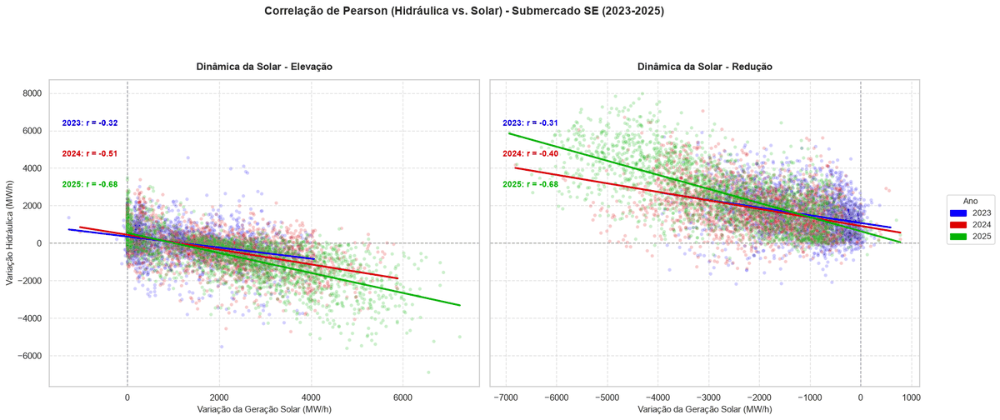

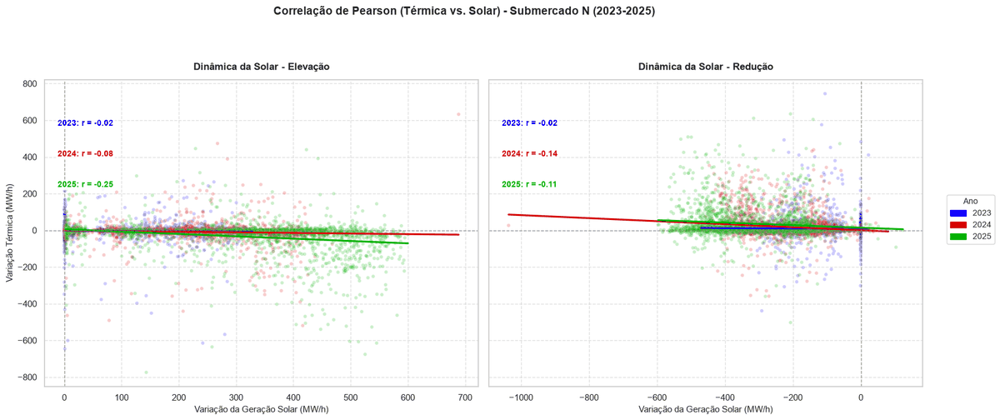

...

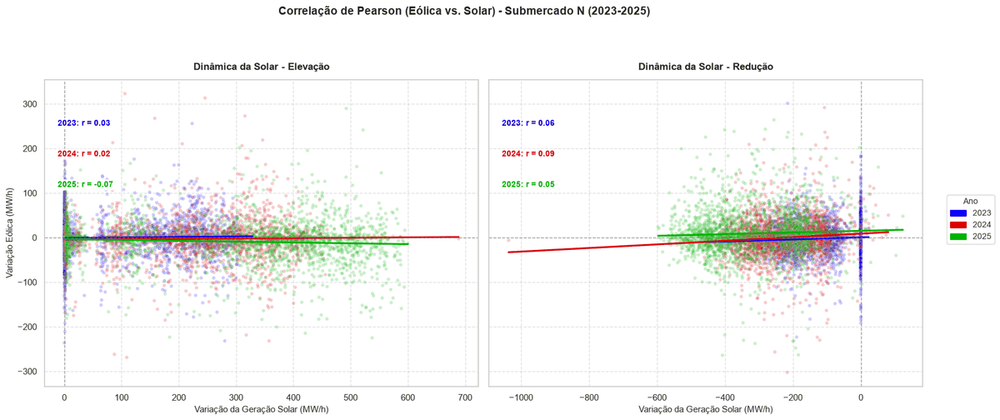

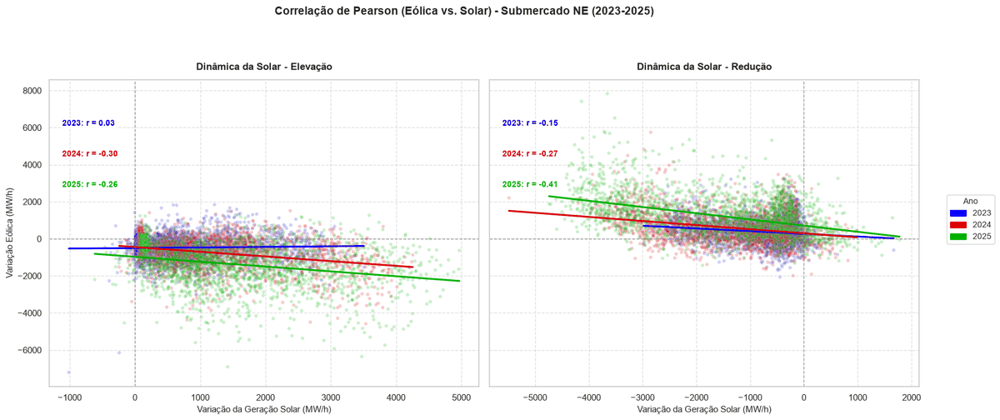

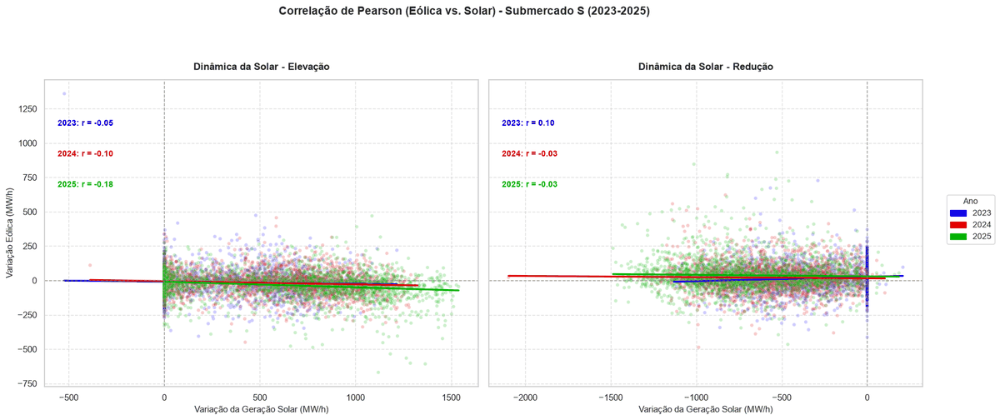

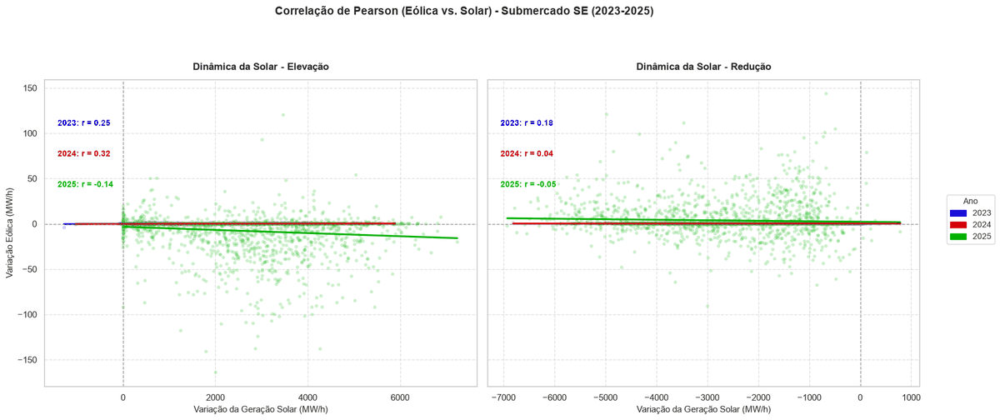

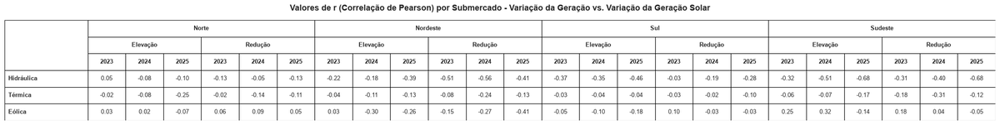

In [22]:
# Script para análise da correlação entre a geração solar e outras fontes (hidráulica, térmica e eólica) nos submercados SE, S, NE e N para os anos de 2023, 2024 e 2025.

lista_consolidada = []

for ano, df in dataframes.items():
  if str(ano) in ['2023', '2024', '2025']:
    df_sub = df[df['id_subsistema'].isin(['SE', 'S', 'NE', 'N'])].copy()
    df_sub['hora'] = df_sub['din_instante'].dt.hour
    df_sub['ano'] = str(ano)
    lista_consolidada.append(df_sub)

df_total = pd.concat(lista_consolidada, ignore_index=True)


# 2. Função para classificar os dados nas janelas operativas corretas da Solar
def classifica_janela_solar(hora):
  if 5 <= hora <= 10:
    return 'Dinâmica da Solar - Elevação'
  elif 13 <= hora <= 18:
    return 'Dinâmica da Solar - Redução'
  return 'Fora das Janelas'


df_total['janela'] = df_total['hora'].apply(classifica_janela_solar)
df_foco = df_total[df_total['janela'] != 'Fora das Janelas']

submercados = sorted(df_foco['id_subsistema'].unique())
janelas_disponiveis = ['Dinâmica da Solar - Elevação','Dinâmica da Solar - Redução',]

pares_comparacao = [
    {
        'col_y': 'var_val_gerhidraulica',
        'nome': 'Hidráulica vs. Solar',
        'ylabel': 'Variação Hidráulica (MW/h)',
    },
    {
        'col_y': 'var_val_gertermica',
        'nome': 'Térmica vs. Solar',
        'ylabel': 'Variação Térmica (MW/h)',
    },
    {
        'col_y': 'var_val_gereolica',
        'nome': 'Eólica vs. Solar',
        'ylabel': 'Variação Eólica (MW/h)',
    },
]

paleta_anos = {'2023': '#1201fc', '2024': '#d90202', '2025': '#00b100'}
sns.set_theme(style='whitegrid')

resultados_r = []

# 3. Loop por Submercado e por Par de Comparação com a Solar
for par in pares_comparacao:
  for sub in submercados:
    df_sub = df_foco[df_foco['id_subsistema'] == sub]

    fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

    for coluna_idx, janela in enumerate(janelas_disponiveis):
      ax = axes[coluna_idx]
      dados_janela = df_sub[df_sub['janela'] == janela]

      sns.scatterplot(
          data=dados_janela,
          x='var_val_gersolar',
          y=par['col_y'],
          hue='ano',
          palette=paleta_anos,
          alpha=0.20,
          s=18,
          ax=ax,
          legend=False,
      )

      y_text_offset = 0.85
      for ano, cor in paleta_anos.items():
        dados_ano = dados_janela[dados_janela['ano'] == ano]
        if not dados_ano.empty:
          sns.regplot(
              data=dados_ano,
              x='var_val_gersolar',
              y=par['col_y'],
              color=cor,
              scatter=False,
              ax=ax,
              ci=None,
              line_kws={'linewidth': 2.2},
          )

          r_val = dados_ano['var_val_gersolar'].corr(
              dados_ano[par['col_y']], method='pearson'
          )

          resultados_r.append({
              'fonte': par['nome'].split(' vs.')[0],
              'submercado': sub,
              'janela': janela,
              'ano': ano,
              'r': r_val,
          })
          ax.text(
              0.03,
              y_text_offset,
              f'{ano}: r = {r_val:.2f}'
              if not pd.isna(r_val)
              else f'{ano}: r = N/A',
              transform=ax.transAxes,
              fontsize=10,
              fontweight='bold',
              color=cor,
              bbox=dict(
                  boxstyle='round,pad=0.2',
                  facecolor='white',
                  alpha=0.85,
                  edgecolor='none',
              ),
          )
          y_text_offset -= 0.10

      ax.set_title(f'{janela}', fontsize=12, fontweight='bold', pad=12)
      ax.set_xlabel('Variação da Geração Solar (MW/h)', fontsize=11)
      ax.set_ylabel(par['ylabel'], fontsize=11)
      ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
      ax.axvline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
      ax.grid(True, linestyle='--', alpha=0.6)


    handles = [Patch(color=cor, label=ano) for ano, cor in paleta_anos.items()]
    fig.legend(
        handles,
        list(paleta_anos.keys()),
        title='Ano',
        loc='center left',
        bbox_to_anchor=(1.01, 0.5),
        fontsize=10,
        title_fontsize=10,
    )

    plt.suptitle(
        f'Correlação de Pearson ({par["nome"]}) - Submercado {sub} (2023-2025)',
        fontsize=14,
        fontweight='bold',
        y=1.02,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# 4. Tabela consolidada dos valores de r (Correlação de Pearson)
from matplotlib.patches import Rectangle

r_lookup = {
    (res['fonte'], res['submercado'], res['janela'], res['ano']): res['r']
    for res in resultados_r
}

fontes_tabela = ['Hidráulica', 'Térmica', 'Eólica']
anos_tabela = list(paleta_anos.keys())
submercados_tabela = [
    ('Norte', 'N'),
    ('Nordeste', 'NE'),
    ('Sul', 'S'),
    ('Sudeste', 'SE'),
]
janelas_tabela = [
    ('Elevação', 'Dinâmica da Solar - Elevação'),
    ('Redução', 'Dinâmica da Solar - Redução'),
]

largura_rotulo = 2.2
cols_por_sub = len(janelas_tabela) * len(anos_tabela)
total_largura = largura_rotulo + len(submercados_tabela) * cols_por_sub
n_linhas = 3 + len(fontes_tabela)

fig, ax = plt.subplots(figsize=(22, 2.9))
ax.set_xlim(0, total_largura)
ax.set_ylim(0, n_linhas)
ax.invert_yaxis()
ax.axis('off')


def desenha_celula(x, y, w, h, texto='', bold=False, fontsize=9, ha='center'):
  ax.add_patch(
      Rectangle((x, y), w, h, fill=False, edgecolor='black', linewidth=0.8)
  )
  if texto:
    x_texto = x + w / 2 if ha == 'center' else x + 0.1
    ax.text(
        x_texto,
        y + h / 2,
        texto,
        ha=ha,
        va='center',
        fontsize=fontsize,
        fontweight='bold' if bold else 'normal',
    )


# Cabeçalhos (3 níveis: submercado, janela e ano)
desenha_celula(0, 0, largura_rotulo, 3)
for s_idx, (titulo_sub, _) in enumerate(submercados_tabela):
  x_sub = largura_rotulo + s_idx * cols_por_sub
  desenha_celula(x_sub, 0, cols_por_sub, 1, titulo_sub, bold=True)
  for j_idx, (titulo_janela, _) in enumerate(janelas_tabela):
    x_janela = x_sub + j_idx * len(anos_tabela)
    desenha_celula(x_janela, 1, len(anos_tabela), 1, titulo_janela, bold=True)
    for a_idx, ano_tab in enumerate(anos_tabela):
      desenha_celula(x_janela + a_idx, 2, 1, 1, ano_tab, bold=True)

for f_idx, fonte in enumerate(fontes_tabela):
  y_linha = 3 + f_idx
  desenha_celula(0, y_linha, largura_rotulo, 1, fonte, bold=True, ha='left')
  x_col = largura_rotulo
  for _, cod_sub in submercados_tabela:
    for _, nome_janela in janelas_tabela:
      for ano_tab in anos_tabela:
        r = r_lookup.get((fonte, cod_sub, nome_janela, ano_tab))
        texto = f'{r:.2f}' if r is not None and not pd.isna(r) else 'N/A'
        desenha_celula(x_col, y_linha, 1, 1, texto)
        x_col += 1

ax.set_title(
    'Valores de r (Correlação de Pearson) por Submercado - Variação da'
    ' Geração vs. Variação da Geração Solar',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.tight_layout()
plt.show()
